# Waze Seguro de Medellín
---

**Fundamentos de IA** · Samuel Ramirez, Andres Montoya, Emanuel Quintero, Pablo Gil, Sebastian Perez, Pedro Rueda

---

Nuestro proposito es hacer un waze "seguro" para medellin sin embargo, una misma ruta no es igual de buena a las 8 de la mañana que a las 11 de la noche. Por lo tanto el mapa de calles de Medellín, le pega a cada calle **qué tan insegura es en cada franja del día (nosotros decidimos las franjas)**, y luego buscamos rutas con los algoritmos de búsqueda vistos en clase.

### Fuentes de Datos

- `hurto_a_persona.csv`, `hurto_de_moto.csv`, `hurto_de_carro.csv`, `hurto_por_pirateria_terrestre.csv` los usamos para contar robos cerca de cada calle, separados por franja horaria (como ya explicamos)
- `202608091356-ansv-fotodeteccion.csv` los usamos para marcar qué calles tienen cámara (solo Medellín) y estas decidimos usarlas para "incrementar" la seguridad de esa calle. 
- `velocidad_e_intensidad_vehicular_en_medellin.csv` la usamos para la velocidad real de las calles que tienen esa información. 

### Decisiones del diseño del mapa

1. Ponemos **todo en metros, nada en grados.** Osea el mapa se proyecta a coordenadas planas, así que las distancias son euclidianas de toda la vida: `√((x₂-x₁)² + (y₂-y₁)²)`, nos parecio mas facil interpretar ubicaciones de esta forma. 
2. Tenemos **dos tablas.** Los nodos van a un DataFrame y las aristas a otro. Toda la información se le agrega a la tabla de aristas que es la que manda. Asi como en el ejemplo del mapa de envigado que agregamos "los parametros" a el dataframe de las aristas que representan las calles. 
3. Comparamos en las funciones con **un peso simple, explicable y en la misma unidad de distancia.** Hacemos que la calle insegura simplemente "se siente más larga".
4. Usamos los **algoritmos de clase:** costo uniforme, best first y A\*.

## 0. Instalación

In [1]:
# Instala lo que falte y verifica que esté todo. Se puede volver a correr.
# Aviso importante: osmnx decide si puede dibujar mapas EN EL MOMENTO en que
# se importa. Si se importa antes de que matplotlib exista, se queda sin
# dibujo el resto de la sesión.
import importlib, subprocess, sys

PAQUETES = { # Paquetes a instalar
    "numpy": "numpy", "pandas": "pandas", "networkx": "networkx",
    "scipy": "scipy", "osmnx": "osmnx", "geopandas": "geopandas",
    "shapely": "shapely", "pyproj": "pyproj", "geopy": "geopy",
    "requests": "requests", "matplotlib": "matplotlib",
}

faltan = [pip for pip, imp in PAQUETES.items() if importlib.util.find_spec(imp) is None] # Revisa si falta algún paquete
# Si faltan paquetes, los instala y reinicia la cache de importlib. Si no, avisa que todo está instalado.
if faltan:
    print("Instalando:", ", ".join(faltan))
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *faltan])
    importlib.invalidate_caches()
else:
    print("Todo instalado.")

if "osmnx" in sys.modules:
    from osmnx import plot as _p
    if not getattr(_p, "mpl_available", True):
        print("\n*** REINICIA EL KERNEL Y VUELVE A EJECUTAR ***")

Todo instalado.


In [2]:
import re, unicodedata, heapq, warnings # re es para expresiones regulares, unicodedata para normalizar strings, heapq para colas de prioridad, warnings para ignorar warnings
from pathlib import Path # Path es para manejar rutas de archivos de manera más cómoda

import numpy as np 
import pandas as pd
import networkx as nx
import osmnx as ox
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree      # búsqueda de vecinos en coordenadas planas
from pyproj import Transformer

warnings.filterwarnings("ignore") # Ignora los warnings de matplotlib y geopandas, que son molestos y no afectan el resultado
pd.set_option("display.max_columns", 40) # Muestra hasta 40 columnas de un DataFrame al imprimirlo
plt.rcParams["figure.figsize"] = (11, 5) # Tamaño de las figuras de matplotlib

print("osmnx", ox.__version__) # Muestra la versión de osmnx

osmnx 2.1.1


## 1. Configuración

Aquí está todo lo que se puede tocar sin meterse en el código.

In [3]:
CARPETA_DATOS = Path("datos") # buscamos los datos en la carpeta "datos"
CARPETA_CACHE = Path("cache");   CARPETA_CACHE.mkdir(exist_ok=True) 
# Creamos la carpeta "cache" si no existe, para guardar los datos descargados de OSM
# la carpeta cache sirve para que no se descarguen los mismos datos una y otra vez, antes de usar osmnx, porque si no, osmnx no guarda nada y se vuelve a descargar todo cada vez que se corre el notebook
CARPETA_SALIDA = Path("salidas"); CARPETA_SALIDA.mkdir(exist_ok=True) # Creamos la carpeta "salidas" si no existe, para guardar los resultados del análisis

CIUDAD = "Medellín, Antioquia, Colombia" # Nombre de la ciudad que vamos a analizar

# SISTEMAS DE COORDENADAS
# Trabajamos en dos sistemas y conviene tener claro para qué sirve cada uno:
#
#   EPSG:4326  -> grados (latitud/longitud). Es lo que entienden OSM y Folium.
#   EPSG:3116  -> metros (MAGNA-SIRGAS Bogotá). Es un PLANO. Aquí calculamos.
#
# Elegimos el 3116 porque el archivo de velocidad ya viene en ese sistema.
# y se nos hizo mas facil interpretarlo. 
SISTEMA_GRADOS = "EPSG:4326"
SISTEMA_METROS = "EPSG:3116"

# FRANJAS HORARIAS
# (nombre, hora_inicio, hora_fin). La noche cruza la medianoche.
FRANJAS = {
    "manana": (6, 12),    # 06:00 - 11:59
    "tarde":  (12, 19),   # 12:00 - 18:59
    "noche":  (19, 6),    # 19:00 - 05:59
}

# PARÁMETROS DEL ANÁLISIS, sirve hacerlo con radios porque los datos vienen con coordenadas entonces hay que asociar esas coordenadas a las calles. 
ANIO_MINIMO = 2019      # solo robos recientes (vimos que tenian datos super viejos entonces descartamos esos)
RADIO_ROBOS = 300       # metros: qué tan cerca cuenta un robo para una calle, hay datos que no vienen por calles 
RADIO_CAMARAS = 300     # metros: alcance de una cámara
RADIO_SENSORES = 700    # metros: distancia máxima para usar un sensor de velocidad

# Caja de Medellín, para descartar coordenadas mal escritas, el mapa se veia muy raro por unos datos que estaban muy lejos de Medellín, entonces se decidió descartar esos datos.
LAT_MIN, LAT_MAX = 6.13, 6.40 
LON_MIN, LON_MAX = -75.72, -75.47  

# Conversores entre los dos sistemas (se usan en varias celdas)
# Transformer.from_crs(origen, destino, always_xy=True) crea un objeto que convierte coordenadas de un sistema a otro. always_xy=True asegura que siempre se use (longitud, latitud) en lugar de (latitud, longitud).
a_metros = Transformer.from_crs(SISTEMA_GRADOS, SISTEMA_METROS, always_xy=True)
a_grados = Transformer.from_crs(SISTEMA_METROS, SISTEMA_GRADOS, always_xy=True)

print("Franjas:", {k: f"{a:02d}:00-{b:02d}:00" for k, (a, b) in FRANJAS.items()})

Franjas: {'manana': '06:00-12:00', 'tarde': '12:00-19:00', 'noche': '19:00-06:00'}


## 2. Los robos

De la columna `fecha_hecho` sacamos **año** y **hora**, y con la hora clasificamos cada robo
en su franja. Un robo a las 21:30 cuenta para la noche y no para la mañana.

In [4]:
# Revisar individualmente cada archivo de robos
ARCHIVOS_ROBOS = [ # archivos de robos que vamos a usar vienen de meddata que es de la alcaldía de medellín, y son datos abiertos.
    "hurto_a_persona.csv",
    "hurto_de_moto.csv",
    "hurto_de_carro.csv",
    "hurto_por_pirateria_terrestre.csv",
]
# # Lo hice para comprobar que columnas tiene cada uno. 
for archivo in ARCHIVOS_ROBOS:
    df = pd.read_csv(CARPETA_DATOS / archivo, low_memory=False)

    print("\n" + "=" * 70)
    print(f"ARCHIVO: {archivo}")
    print(f"NÚMERO DE REGISTROS: {len(df):,}")
    print(f"NÚMERO DE COLUMNAS: {len(df.columns)}")

    print("\nCOLUMNAS:")
    print(list(df.columns))

    print("\nNULOS POR COLUMNA:")
    print(df.isnull().sum())

# Resumen de los archivos de robos: registros, columnas y nulos. Esta es la version "linda"
resumen = []

for archivo in ARCHIVOS_ROBOS:
    df = pd.read_csv(CARPETA_DATOS / archivo, low_memory=False)

    resumen.append({
        "Archivo": archivo,
        "Registros": len(df),
        "Columnas": len(df.columns),
        "Nulos fecha": df["fecha_hecho"].isna().sum(),
        "Nulos latitud": df["latitud"].isna().sum(),
        "Nulos longitud": df["longitud"].isna().sum(),
        "Nulos totales": df.isna().sum().sum()
    })

resumen = pd.DataFrame(resumen)

resumen


ARCHIVO: hurto_a_persona.csv
NÚMERO DE REGISTROS: 326,489
NÚMERO DE COLUMNAS: 36

COLUMNAS:
['fecha_hecho', 'cantidad', 'latitud', 'longitud', 'sexo', 'edad', 'estado_civil', 'grupo_actor', 'actividad_delictiva', 'parentesco', 'ocupacion', 'discapacidad', 'grupo_especial', 'medio_transporte', 'nivel_academico', 'testigo', 'conducta', 'modalidad', 'caracterizacion', 'conducta_especial', 'arma_medio', 'articulo_penal', 'categoria_penal', 'nombre_barrio', 'codigo_barrio', 'codigo_comuna', 'lugar', 'sede_receptora', 'bien', 'categoria_bien', 'grupo_bien', 'modelo', 'color', 'permiso', 'unidad_medida', 'fecha_ingestion']

NULOS POR COLUMNA:
fecha_hecho                0
cantidad                   0
latitud                41944
longitud               41944
sexo                       0
edad                       0
estado_civil               0
grupo_actor                0
actividad_delictiva        0
parentesco                 0
ocupacion                  0
discapacidad               0
grupo_e

,Archivo,Registros,Columnas,Nulos fecha,Nulos latitud,Nulos longitud,Nulos totales
0,hurto_a_persona.csv,326489,36,0,41944,41944,83888
1,hurto_de_moto.csv,86410,36,0,17447,17447,34894
2,hurto_de_carro.csv,39571,36,0,10141,10141,20282
3,hurto_por_pirateria_terrestre.csv,2202,36,0,725,725,1450


In [5]:
ARCHIVOS_ROBOS = [ # archivos de robos que vamos a usar vienen de meddata que es de la alcaldía de medellín, y son datos abiertos.
    "hurto_a_persona.csv",
    "hurto_de_moto.csv",
    "hurto_de_carro.csv",
    "hurto_por_pirateria_terrestre.csv",
]

COLUMNAS = ["fecha_hecho", "latitud", "longitud", "nombre_barrio", "lugar", "modalidad"]
# Aparecen iguales en los 4 csv. 

def clasificar_franja(hora):
    # Devuelve "manana", "tarde" o "noche" según la hora (0-23)
    if 6 <= hora < 12:
        return "manana"
    if 12 <= hora < 19:
        return "tarde"
    return "noche"          # 19:00-23:59 y 00:00-05:59

partes = [] # lista de DataFrames, uno por cada archivo de robos

# Recorremos uno por uno los nombres de los archivos que están guardados en ARCHIVOS_ROBOS.
# En cada iteración, "archivo" toma el nombre de un CSV diferente.
for archivo in ARCHIVOS_ROBOS:
    # Leemos el archivo CSV utilizando pandas.
    # CARPETA_DATOS / archivo construye la ruta del archivo dentro de la carpeta "datos".
    # usecols=COLUMNAS indica que solo queremos cargar las columnas que definimos anteriormente.
    # low_memory=False evita que pandas intente adivinar los tipos de datos por partes,
    # lo que puede ser útil cuando los CSV tienen muchas filas o columnas con tipos mezclados.
    t = pd.read_csv(CARPETA_DATOS / archivo, usecols=COLUMNAS, low_memory=False)

    # Creamos una nueva columna llamada "tipo_robo".
    # Tomamos el nombre del archivo y eliminamos "hurto_" y ".csv".
    # Por ejemplo: "hurto_a_persona.csv" se convierte en "a_persona".
    t["tipo_robo"] = archivo.replace("hurto_", "").replace(".csv", "")
    partes.append(t)

    print(f"  {archivo:38s} {len(t):>7,} filas") # Mostramos en pantalla el nombre del archivo y la cantidad de filas que contiene. :38s reserva 38 espacios para el nombre del archivo. :>7, coloca el número alineado a la derecha y utiliza comas como separadores de miles.

robos = pd.concat(partes, ignore_index=True)

# --- extraer año y hora de la fecha ---
# El formato es "2017-01-01T01:00:00.000-05:00", así que basta con cortar el texto:
#   posiciones 0-3   -> año
#   posiciones 11-12 -> hora
fecha = robos["fecha_hecho"].astype(str)
robos["anio"] = pd.to_numeric(fecha.str[:4], errors="coerce")
robos["hora"] = pd.to_numeric(fecha.str[11:13], errors="coerce")

print(f"\nTotal sin filtrar: {len(robos):,}")
robos.head(3)

  hurto_a_persona.csv                    326,489 filas
  hurto_de_moto.csv                       86,410 filas
  hurto_de_carro.csv                      39,571 filas
  hurto_por_pirateria_terrestre.csv        2,202 filas

Total sin filtrar: 454,672


,fecha_hecho,latitud,longitud,modalidad,nombre_barrio,lugar,tipo_robo,anio,hora
0,2017-01-01T01:00:00.000-05:00,6.299703,-75.582016,Atraco,Doce de Octubre No.2,Vía pública,a_persona,2017,1
1,2017-01-01T15:00:00.000-05:00,6.250917,-75.566160,Atraco,La Candelaria,Vía pública,a_persona,2017,15
2,2017-01-01T14:00:00.000-05:00,6.274836,-75.554909,Descuido,Campo Valdés No.1,Vía pública,a_persona,2017,14


In [6]:
# LIMPIEZA DE LOS ROBOS
antes = len(robos)

# Las coordenadas vienen como texto en algunas filas; 
# errors="coerce" convierte lo que no se pueda parsear en NaN en vez de reventar.
robos["latitud"]  = pd.to_numeric(robos["latitud"],  errors="coerce")
robos["longitud"] = pd.to_numeric(robos["longitud"], errors="coerce")

# 1. Fuera las filas sin ubicación o sin fecha utilizable (mas o menos 15% del total)
robos = robos.dropna(subset=["latitud", "longitud", "hora", "anio"])

# 2. Fuera las coordenadas imposibles. Hay filas con longitud -0,0007 que estan fuera de la caja de Medellín
robos = robos[robos["latitud"].between(LAT_MIN, LAT_MAX)]
robos = robos[robos["longitud"].between(LON_MIN, LON_MAX)]

# 3. Solo años recientes: antes de 2019 
robos = robos[robos["anio"] >= ANIO_MINIMO]

# 4. Clasificar cada robo en su franja según la hora
robos["franja"] = robos["hora"].astype(int).apply(clasificar_franja)

# 5. Pasar de grados a METROS. A partir de aquí los robos viven en el mismo
#    plano que el grafo, y se pueden cruzar con distancias euclidianas.
#    transform espera (longitud, latitud) en ese orden, no al revés.
x, y = a_metros.transform(robos["longitud"].values, robos["latitud"].values)
robos["x"] = x
robos["y"] = y

robos = robos.reset_index(drop=True) # Reindexamos el DataFrame para que los índices sean consecutivos después de eliminar filas.

print(f"{antes:,} -> {len(robos):,} robos utilizables " # el :, formatea el número con comas como separadores de miles
      f"(se descartó el {(1-len(robos)/antes)*100:.1f}%)\n")
print(robos["franja"].value_counts().to_string())
robos[["anio", "hora", "franja", "tipo_robo", "nombre_barrio", "x", "y"]].head()

454,672 -> 170,456 robos utilizables (se descartó el 62.5%)

franja
noche     74834
tarde     51150
manana    44472


,anio,hora,franja,tipo_robo,nombre_barrio,x,y
0,2020,15,tarde,a_persona,Villa Nueva,835399.627984,1.183625e+06
1,2020,6,manana,a_persona,Los Cerros el Vergel,837605.079577,1.181273e+06
2,2020,7,manana,a_persona,El Salvador,835522.553964,1.181529e+06
3,2020,11,manana,a_persona,Villa Nueva,835669.011344,1.183617e+06
4,2020,11,manana,a_persona,El Salado,829034.458907,1.183596e+06


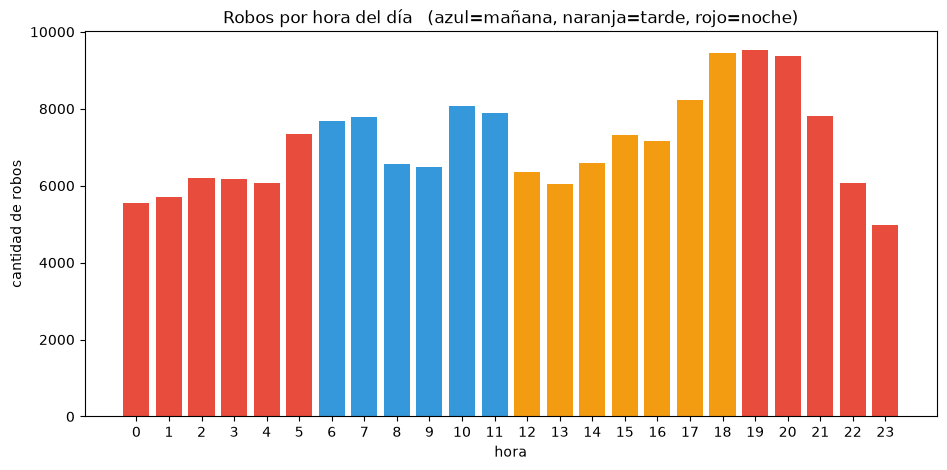

tipo_robo,a_persona,de_carro,de_moto,por_pirateria_terrestre
franja,,,,
manana,38889,928,4654,1
noche,61815,1953,11066,0
tarde,46199,898,4044,9


In [7]:
# ¿A qué hora roban más? Esto es lo que justifica separar por franjas.
conteo_hora = robos.groupby("hora").size()
colores = ["#e74c3c" if clasificar_franja(h) == "noche"
           else "#f39c12" if clasificar_franja(h) == "tarde"
           else "#3498db" for h in conteo_hora.index]

plt.bar(conteo_hora.index, conteo_hora.values, color=colores)
plt.title("Robos por hora del día   (azul=mañana, naranja=tarde, rojo=noche)")
plt.xlabel("hora"); plt.ylabel("cantidad de robos"); plt.xticks(range(0, 24))
plt.show()

resumen = robos.groupby(["franja", "tipo_robo"]).size().unstack(fill_value=0)
display(resumen)

Vimos que por_pirateria_terrestre solo mete 10 datos 

### Decisiones sobre los archivos de hurto

| Decisión | Por qué |
|---|---|
| **Juntar los 4 archivos en una sola tabla** | Comparten exactamente el mismo esquema de columnas. A efectos de "por aquí roban", da igual si te quitaron el celular o la moto. |
| **Todos los robos pesan igual** | Se podría dar más peso al de carro que al hurto a persona, pero eso mete un parámetro más que habría que justificar y realmente robo es robo no importa a quien. Con peso igual, el número que sale es literal: *cuántos robos hubo cerca*. |
| **Solo desde 2019** | Los datos llegan hasta 2022-2023. Antes de 2019 el registro es mucho más flojo (1.894 casos en 2011 frente a 45.502 en 2019), así que mezclarlos deformaría el mapa: parecería que había menos delito donde en realidad había menos denuncia registrada y también es un registro muy viejo. |
| **Descartar las filas sin coordenada** | Es el **15%** de los registros mas o menos y no hay forma de ubicarlos. Ademas que un robo sin coordenadas no aprota mucha información, se podria usar el barrio pero castiga a todo el barrio sin tener la informacion clara de donde. |
| **Filtrar por una caja de coordenadas** | Hay datos mal insertados: una fila tiene longitud -0,0007. Y este tipo de registros son todos basura para nuestro caso. |
| **Franjas en vez de hora exacta** | Con 24 columnas de inseguridad el modelo sería más fino pero mucho menos explicable, y cada hora tendría menos datos. Tres franjas dejan suficientes robos en cada una para que el conteo sea estable. |

## 3. Las cámaras

Del registro nacional nos quedamos **solo con Medellín** y solo con las que están funcionando.
Una cámara vencida no sirve de nada.

In [8]:
# Inspección del archivo de cámaras de fotodetección
ARCHIVO_CAMARAS = "202608091356-ansv-fotodeteccion.csv"

df_camaras = pd.read_csv(CARPETA_DATOS / ARCHIVO_CAMARAS, low_memory=False)

print(f"ARCHIVO: {ARCHIVO_CAMARAS}")
print(f"NÚMERO DE REGISTROS: {len(df_camaras):,}")
print(f"NÚMERO DE COLUMNAS: {len(df_camaras.columns)}")

print("\nCOLUMNAS:")
print(list(df_camaras.columns))

print("\nNULOS POR COLUMNA:")
print(df_camaras.isna().sum())

print("\nPRIMERAS FILAS:")
display(df_camaras.head())

ARCHIVO: 202608091356-ansv-fotodeteccion.csv
NÚMERO DE REGISTROS: 1,335
NÚMERO DE COLUMNAS: 27

COLUMNAS:
['Acciones', 'Código solicitud', 'Código unico', 'Estado operación', 'Departamento', 'Municipio', 'Fecha aprobación', 'Dirección', 'Autoridad de tránsito', 'Jurisdicción', 'Infracciones', 'Velocidad', 'Tipo de tecnología', 'Tipo de instalación', 'Nombre equipo', 'Latitud', 'Longitud', 'Código equipo', 'Resolución de renovación', 'Fecha radicación de renovación', 'Fecha de notificación', 'Fecha de recurso', 'Fecha resolución de recurso', 'Fecha de aprobación final', 'Fecha finalización de prórroga', 'Fecha inicio de operación', 'Fecha finalización inicial']

NULOS POR COLUMNA:
Acciones                          1335
Código solicitud                     0
Código unico                         1
Estado operación                     0
Departamento                         0
Municipio                            0
Fecha aprobación                     0
Dirección                            0

,Acciones,Código solicitud,Código unico,Estado operación,Departamento,Municipio,Fecha aprobación,Dirección,Autoridad de tránsito,Jurisdicción,Infracciones,Velocidad,Tipo de tecnología,Tipo de instalación,Nombre equipo,Latitud,Longitud,Código equipo,Resolución de renovación,Fecha radicación de renovación,Fecha de notificación,Fecha de recurso,Fecha resolución de recurso,Fecha de aprobación final,Fecha finalización de prórroga,Fecha inicio de operación,Fecha finalización inicial
0,NaN,SOL0000003562,CU000000000533,Renovada - Expirada,VALLE DEL CAUCA,SAN PEDRO,13/02/2021,Troncal de Occidente Km 83+600 MUNICIPIO DE SA...,SECRETARÍA DE MOVILIDAD Y TRANSPORTE DEL VALLE...,Departamental,"C.26, C.29, C.35, D.2",NaN,Radar Doppler,Móvil,0X00031753,4.009215,-76.223208,NaN,NaN,12/12/2025,NaN,NaN,NaN,NaN,NaN,NaN,12/02/2026
1,NaN,SOL0000003544,CU000000000530,Renovada - Expirada,VALLE DEL CAUCA,SAN PEDRO,12/02/2021,Troncal de Occidente Km 83+600,SECRETARÍA DE MOVILIDAD Y TRANSPORTE DEL VALLE...,Departamental,"C.26, C.29, C.35, D.2",NaN,Radar Doppler,Móvil,0X00031748,4.009318,-76.223496,NaN,NaN,12/12/2025,NaN,NaN,NaN,NaN,NaN,NaN,11/02/2026
2,NaN,SOL0000002623,CU000000000515,Prorrogada - Vencida,CESAR,SAN ALBERTO,10/11/2020,"Vía San Alberto - La Mata, Ruta 4514 PR 1+499",INSTITUTO DEPARTAMENTAL DE TRANSITO DEL CESAR,Nacional,"C.24, C.29, C.35, D.10, D.2",NaN,Radar Doppler,Fijo,C1,7.784671,-73.401922,NaN,86.0,22/11/2025,28/01/2026,NaN,NaN,NaN,11/02/2026,NaN,09/11/2025
3,NaN,SOL0000003543,CU000000000528,Prorrogada - Vencida,VALLE DEL CAUCA,SAN PEDRO,12/02/2021,Troncal de Occidente Km 80+600 Municipio San p...,SECRETARÍA DE MOVILIDAD Y TRANSPORTE DEL VALLE...,Departamental,"C.26, C.29, C.35, D.2",NaN,Radar Doppler,Móvil,0X00030819,3.986661,-76.237873,NaN,138.0,24/10/2025,16/02/2026,NaN,NaN,NaN,02/03/2026,NaN,11/02/2026
4,NaN,SOL0000002641,CU000000000516,Prorrogada - Vencida,CESAR,SAN ALBERTO,10/11/2020,"Vía San Alberto - La Mata, Ruta 4514 PR 3+935",INSTITUTO DEPARTAMENTAL DE TRANSITO DEL CESAR,Nacional,"C.24, C.29, C.35, D.10, D.2",NaN,Radar Doppler,Fijo,C2,7.804725,-73.412052,NaN,106.0,22/10/2025,03/02/2026,NaN,NaN,NaN,17/02/2026,NaN,09/11/2025


In [9]:
camaras = pd.read_csv(CARPETA_DATOS / "202608091356-ansv-fotodeteccion.csv", low_memory=False) #low_memory=False evita que pandas intente adivinar los tipos de datos por partes, lo que puede ser útil cuando los CSV tienen muchas filas o columnas con tipos mezclados.
camaras.columns = [c.strip() for c in camaras.columns] #.strip() elimina espacios en blanco al inicio y al final de cada nombre de columna, para evitar problemas al acceder a ellas.
print(f"Registro nacional completo: {len(camaras):,} cámaras")

# 1. solo Medellín 
municipio = camaras["Municipio"].astype(str).str.upper().str.strip() # el .upper() convierte todo a mayúsculas 
camaras = camaras[municipio.isin(["MEDELLIN", "MEDELLÍN"])].copy()
print(f"Solo Medellín: {len(camaras)}")

# 2. solo las que operan 
ESTADOS_BUENOS = ["Operando", "Autorizada instalar", "Prorrogada"]
camaras = camaras[camaras["Estado operación"].isin(ESTADOS_BUENOS)]
print(f"Solo las activas: {len(camaras)}")

# Aca convertimos las coordenadas de las cámaras a números y eliminamos las filas que no tienen coordenadas
camaras["latitud"]  = pd.to_numeric(camaras["Latitud"],  errors="coerce")
camaras["longitud"] = pd.to_numeric(camaras["Longitud"], errors="coerce")
camaras = camaras.dropna(subset=["latitud", "longitud"])

x, y = a_metros.transform(camaras["longitud"].values, camaras["latitud"].values)
camaras["x"] = x
camaras["y"] = y
camaras = camaras.reset_index(drop=True)

print(f"\nCámaras finales: {len(camaras)}")
display(camaras["Tipo de tecnología"].value_counts())

Registro nacional completo: 1,335 cámaras
Solo Medellín: 133
Solo las activas: 51

Cámaras finales: 51


Tipo de tecnología
Radar Doppler    51
Name: count, dtype: int64

### Decisiones sobre las cámaras

| Decisión | Por qué |
|---|---|
| **Solo Medellín** | El archivo es el registro nacional (1.335 cámaras). En Antioquia hay 249 y en Medellín 133 |
| **Solo las que operan** | Menos de la mitad están activas. Una cámara *Vencida* o *Renovada - Expirada* no sirve. |
| **Contar "hay o no hay", no cuántas** | Se usa `tiene_camara` (0 o 1) y no el número. Con tan pocas cámaras, contar cuántas hay cerca mete ruido sin aportar nada, por eso despues se dara una pequeña bonificacion si hay o no hay camara a la seguridad. |

## 4. La velocidad real

Este archivo trae dos cosas raras:

1. Las columnas `longitud` y `latitud` **no son grados**: son metros en EPSG:3116.
   Como nosotros vamos a trabajar justo en ese sistema, nos las quedamos tal cual. La latitud del planeta solamente puede estar entre: -90° y +90°. y los datos vienen con cosas como longitud = 826542.6250 latitud = 1186316.75. No tienen sentido.
2. Usa **coma decimal** en vez de punto.

In [10]:
# Inspección del archivo de velocidad e intensidad vehicular
ARCHIVO_VELOCIDAD = "velocidad_e_intensidad_vehicular_en_medellin.csv"

df_velocidad = pd.read_csv(
    CARPETA_DATOS / ARCHIVO_VELOCIDAD,
    low_memory=False,
    dtype=str
)

print(f"ARCHIVO: {ARCHIVO_VELOCIDAD}")
print(f"NÚMERO DE REGISTROS: {len(df_velocidad):,}")
print(f"NÚMERO DE COLUMNAS: {len(df_velocidad.columns)}")

print("\nCOLUMNAS:")
print(list(df_velocidad.columns))

print("\nNULOS POR COLUMNA:")
print(df_velocidad.isna().sum())

print("\nPRIMERAS FILAS:")
display(df_velocidad.head())

print("\nEJEMPLO DE COORDENADAS Y VELOCIDAD:")
display(df_velocidad[["longitud", "latitud", "velocidad_km_h"]].head(10))

ARCHIVO: velocidad_e_intensidad_vehicular_en_medellin.csv
NÚMERO DE REGISTROS: 431,490
NÚMERO DE COLUMNAS: 25

COLUMNAS:
['carril', 'fecha_trafico', 'fecha', 'hora', 'dia', 'dia_num', 'mes_num', 'mes', 'ano', 'velocidad_km_h', 'corredor', 'sentido', 'operacion', 'intensidad', 'categoria_1', 'categoria_2', 'categoria_3', 'ocupacion', 'tipo_subsistema', 'longitud', 'latitud', 'identificador_f_v', 'comuna', 'codigo_comuna', 'nombre_comuna']

NULOS POR COLUMNA:
carril                   0
fecha_trafico            0
fecha                    0
hora                     0
dia                      0
dia_num                  0
mes_num                  0
mes                      0
ano                      0
velocidad_km_h           0
corredor                 0
sentido                  0
operacion            37550
intensidad               0
categoria_1              0
categoria_2              0
categoria_3              0
ocupacion                0
tipo_subsistema          0
longitud                 

,carril,fecha_trafico,fecha,hora,dia,dia_num,mes_num,mes,ano,velocidad_km_h,corredor,sentido,operacion,intensidad,categoria_1,categoria_2,categoria_3,ocupacion,tipo_subsistema,longitud,latitud,identificador_f_v,comuna,codigo_comuna,nombre_comuna
0,XC-1-BOL-65-ENT:ORI-OCC,1/07/2020 0:00,1/07/2020,0,Miercoles,3,7,Julio,2020,27,Avenida Bolivariana,EW,interrumpido,148,136,9,3,15,ARS,"833291,8125","1182614,75",V,11 - Laureles Estadio,11,Laureles Estadio
1,XC-1-BOL-65-ENT:ORI-OCC,1/07/2020 1:00,1/07/2020,1,Miercoles,3,7,Julio,2020,24,Avenida Bolivariana,EW,interrumpido,73,71,2,0,3,ARS,"833291,8125","1182614,75",V,11 - Laureles Estadio,11,Laureles Estadio
2,XC-1-BOL-65-ENT:ORI-OCC,1/07/2020 2:00,1/07/2020,2,Miercoles,3,7,Julio,2020,21,Avenida Bolivariana,EW,interrumpido,48,46,1,1,4,ARS,"833291,8125","1182614,75",V,11 - Laureles Estadio,11,Laureles Estadio
3,XC-1-BOL-65-ENT:ORI-OCC,1/07/2020 3:00,1/07/2020,3,Miercoles,3,7,Julio,2020,18,Avenida Bolivariana,EW,interrumpido,60,54,5,1,11,ARS,"833291,8125","1182614,75",V,11 - Laureles Estadio,11,Laureles Estadio
4,XC-1-BOL-65-ENT:ORI-OCC,1/07/2020 4:00,1/07/2020,4,Miercoles,3,7,Julio,2020,18,Avenida Bolivariana,EW,interrumpido,91,84,4,3,16,ARS,"833291,8125","1182614,75",V,11 - Laureles Estadio,11,Laureles Estadio



EJEMPLO DE COORDENADAS Y VELOCIDAD:


,longitud,latitud,velocidad_km_h
0,"833291,8125","1182614,75",27
1,"833291,8125","1182614,75",24
2,"833291,8125","1182614,75",21
3,"833291,8125","1182614,75",18
4,"833291,8125","1182614,75",18
5,"833291,8125","1182614,75",23
6,"833291,8125","1182614,75",21
7,"833291,8125","1182614,75",19
8,"833291,8125","1182614,75",19
9,"833291,8125","1182614,75",18


In [11]:
COLS_VEL = ["hora", "velocidad_km_h", "corredor", "sentido", "longitud", "latitud"]
vel = pd.read_csv(CARPETA_DATOS / "velocidad_e_intensidad_vehicular_en_medellin.csv",
                  usecols=COLS_VEL, dtype=str)

# coma decimal -> punto
for c in ["longitud", "latitud"]:
    vel[c] = vel[c].str.replace(",", ".", regex=False).astype(float)
for c in ["hora", "velocidad_km_h"]:
    vel[c] = pd.to_numeric(vel[c], errors="coerce")

# ¡Ojo! Aquí "longitud" y "latitud" ya son X e Y en metros. Solo hay que renombrar.
vel = vel.rename(columns={"longitud": "x", "latitud": "y"})
vel = vel[(vel["velocidad_km_h"] > 0) & (vel["velocidad_km_h"] < 130)]

# Un sensor = un punto (x, y). Promediamos su velocidad.
sensores = (vel.groupby(["x", "y", "corredor"], as_index=False)
               .agg(velocidad_real=("velocidad_km_h", "mean"),
                    mediciones=("velocidad_km_h", "size")))

print(f"{len(vel):,} mediciones en {len(sensores)} sensores")
sensores.head()

425,756 mediciones en 149 sensores


,x,y,corredor,velocidad_real,mediciones
0,826542.6250,1186316.75,V���a al T���nel de Occidente,37.739461,1447
1,826956.5625,1186004.00,V���a al T���nel de Occidente,16.815395,1468
2,829333.0625,1186061.00,V���a al Mar,20.619272,1484
3,830604.8750,1181859.50,Avenida 33,27.957841,2965
4,830676.1875,1183354.50,San Juan,27.525241,1763


### Decisiones sobre el archivo de velocidad

| Decisión | Por qué |
|---|---|
| **Cambiar la coma decimal por punto** | El archivo usa formato español (`833291,8125`). Sin esto, `pandas` lee las coordenadas como texto. |
| **Descartar velocidades de 0 o más de 130** | Un sensor parado marca 0 y rompe la división al calcular el tiempo. Por encima de 130 km/h en ciudad es error de medición. En realidad lo pusimos mas por evitar que una ruta vaya a quedar super rapida o super lenta por error|
| **Promediar por punto de sensor** | Hay 431.490 mediciones repartidas en unos 130 puntos.|
| **Usar el sensor más cercano si está a menos de 700 m** | Es lo más simple que funciona y lo que haremos con los otros datos tambien. Los nombres pueden no coincidir literalmente con OSM. |

## 5. El mapa de calles

Descargamos de OpenStreetMap y **se proyecta a metros**. Después de `project_graph`
las coordenadas `x` e `y` de cada nodo dejan de ser grados y pasan a ser metros sobre
un plano a partir de aqui toda la geometría es euclidiana. Lo que hace mas sencilla su interpretación.

In [12]:
ARCHIVO_GRAFO = CARPETA_CACHE / "medellin_drive.graphml"

VELOCIDADES_POR_TIPO = {
    "motorway": 80, "trunk": 70, "primary": 60, "secondary": 50,
    "tertiary": 40, "residential": 30, "living_street": 20,
    "unclassified": 30, "service": 20, "road": 30,
}

if ARCHIVO_GRAFO.exists():
    print("Cargando el mapa desde cache...")
    grafo_grados = ox.load_graphml(ARCHIVO_GRAFO)
else:
    print("Descargando el mapa de OpenStreetMap (tarda unos minutos)...")
    grafo_grados = ox.graph_from_place(CIUDAD, network_type="drive")
    grafo_grados = ox.add_edge_speeds(grafo_grados, hwy_speeds=VELOCIDADES_POR_TIPO, fallback=30)
    grafo_grados = ox.add_edge_travel_times(grafo_grados)
    ox.save_graphml(grafo_grados, ARCHIVO_GRAFO)

# Proyectar: de grados a metros. Este es el paso que vuelve todo plano.
grafo = ox.project_graph(grafo_grados, to_crs=SISTEMA_METROS)

print(f"\nNodos:   {grafo.number_of_nodes():,}")
print(f"Aristas: {grafo.number_of_edges():,}")
print(f"Sistema de coordenadas: {grafo.graph['crs']}")

Cargando el mapa desde cache...

Nodos:   18,316
Aristas: 43,297
Sistema de coordenadas: EPSG:3116


## 6. Las dos tablas

Aquí pasamos del grafo a **dos DataFrames**:

* **`nodos`**:las esquinas. Cada una con su `x`, `y` en metros y su `lat`, `lon` en grados (los grados solo se usan al final, para dibujar el mapa).
* **`aristas`**: los tramos de calle. Es la tabla importante: aquí le vamos a ir pegando columna por columna toda la información de robos, cámaras y velocidad.

In [13]:
# TABLA DE NODOS
filas = []
for id_nodo, datos in grafo.nodes(data=True):
    filas.append({
        "id_nodo": id_nodo,
        "x": datos["x"],                          # metros
        "y": datos["y"],                          # metros
        "lat": grafo_grados.nodes[id_nodo]["y"],  # grados, solo para dibujar
        "lon": grafo_grados.nodes[id_nodo]["x"],
    })
nodos = pd.DataFrame(filas)

print(f"{len(nodos):,} nodos")
display(nodos.head())

18,316 nodos


,id_nodo,x,y,lat,lon
0,309026271,834490.710023,1.178862e+06,6.211516,-75.572858
1,404910004,834530.443192,1.178846e+06,6.211376,-75.572498
2,309026273,834749.065955,1.178763e+06,6.210624,-75.570522
3,393988726,834760.633913,1.178758e+06,6.210585,-75.570417
4,338171294,834716.844387,1.178678e+06,6.209860,-75.570810


In [14]:
# TABLA DE ARISTAS  (los tramos de calle)
# Esta es la tabla del proyecto: aquí se le van pegando columnas con toda
# la información de robos, cámaras y velocidad.

filas = []
for origen, destino, datos in grafo.edges(data=True):

    # OSM a veces guarda varios nombres para la misma calle. Nos quedamos con el primero.
    nombre = datos.get("name", None)
    if isinstance(nombre, list):
        nombre = nombre[0]

    filas.append({
        "origen": origen,                                  # nodo de partida
        "destino": destino,                                # nodo de llegada
        "distancia_m": float(datos["length"]),             # largo real, siguiendo las curvas
        "nombre_via": nombre,
        "tipo_via": str(datos.get("highway", "")),         # residential, primary, etc.
        "velocidad_osm": float(datos.get("speed_kph", 30)),# velocidad teórica
    })

aristas = pd.DataFrame(filas)
print(f"{len(aristas):,} aristas antes de simplificar")

# Quitar calles duplicadas, esta es la parte que hablamos de que por ejemplo un puente y una calle que van a los mismos nodos donde nos quedamos con el mas corto. 
aristas = (aristas
           .sort_values("distancia_m")                                  # la más corta primero
           .drop_duplicates(subset=["origen", "destino"], keep="first") # y nos quedamos esa
           .reset_index(drop=True))

print(f"{len(aristas):,} aristas después de simplificar")
display(aristas.head())

43,297 aristas antes de simplificar
43,111 aristas después de simplificar


,origen,destino,distancia_m,nombre_via,tipo_via,velocidad_osm
0,9987035814,5510015888,0.682288,NaN,tertiary,40.0
1,9391291818,2667852045,0.843122,NaN,secondary,50.0
2,3513484311,3513470678,1.075969,Calle 32,tertiary,40.0
3,3513470678,3513484311,1.075969,Calle 32,tertiary,40.0
4,13828062837,9673526405,1.079102,Carrera 46,tertiary,30.0


In [15]:
# PUNTO MEDIO DE CADA CALLE

# Problema: los robos, las cámaras y los sensores son PUNTOS sueltos, pero
# las calles son LÍNEAS. Para cruzarlos hay que reducir cada calle a un
# punto, y el más razonable es su punto medio.
# Es una aproximación: en una calle de 500 m, un robo en un extremo queda
# a 250 m del punto medio. Se acepta porque la mayoría de tramos de OSM son
# cortos (unos 98 m de media).

# Índice por id de nodo para poder buscar coordenadas rápido
coord = nodos.set_index("id_nodo")[["x", "y"]]

# .loc con una lista devuelve las filas en ese orden: así alineamos las
# coordenadas de cada arista sin necesidad de un bucle.
x_origen  = coord.loc[aristas["origen"],  "x"].values
y_origen  = coord.loc[aristas["origen"],  "y"].values
x_destino = coord.loc[aristas["destino"], "x"].values
y_destino = coord.loc[aristas["destino"], "y"].values

# Como estamos en METROS sobre un plano, el punto medio es el promedio.
aristas["x_medio"] = (x_origen + x_destino) / 2
aristas["y_medio"] = (y_origen + y_destino) / 2

# Comprobación: distancia real contra línea recta

# Esto no es decorativo. A* necesita que la línea recta NUNCA supere a la
# distancia real, y aquí lo verificamos con datos en vez de suponerlo.
distancia_recta = np.sqrt((x_destino - x_origen)**2 + (y_destino - y_origen)**2)
aristas["distancia_recta_m"] = distancia_recta

print("Distancia real de la calle contra la línea recta:")
print(f"  distancia OSM (sigue las curvas): {aristas['distancia_m'].mean():.1f} m de media")
print(f"  distancia en línea recta:         {distancia_recta.mean():.1f} m de media")
print(f"  la línea recta es un {(1 - distancia_recta.mean()/aristas['distancia_m'].mean())*100:.1f}% más corta")


# La comprobación que de verdad importa para A*

# En teoría la recta nunca debería superar a la distancia real. En la
# práctica sí ocurre un poco, y conviene saber por qué como cambiamos a metros,
# la proyección de OSM no es perfecta.
# EPSG:3116 tiene su meridiano central en -74,08 y Medellín está en -75,57,
# a unos 165 km. A esa distancia la proyección ESTIRA un pelín las medidas.
# Resultado: en tramos rectos y cortos, la recta proyectada sale ligeramente
# mayor que la longitud que calculó OSM y por eso tambien ponemos un 0.998 mas adelante.
exceso = distancia_recta / aristas["distancia_m"]
se_pasan = exceso > 1.0

print(f"\nCalles donde la recta supera a la distancia real: "
      f"{se_pasan.sum():,} de {len(aristas):,} ({se_pasan.mean()*100:.1f}%)")
print(f"Exceso máximo: {(exceso.max()-1)*100:.3f}%  (o sea, nada)")
print("\nEs tan pequeño que en la práctica no cambia ninguna ruta, pero para")
print("no dejar la garantía coja, la heurística lleva un factor de 0.998.")

Distancia real de la calle contra la línea recta:
  distancia OSM (sigue las curvas): 98.3 m de media
  distancia en línea recta:         88.6 m de media
  la línea recta es un 9.8% más corta

Calles donde la recta supera a la distancia real: 9,330 de 43,111 (21.6%)
Exceso máximo: 0.155%  (o sea, nada)

Es tan pequeño que en la práctica no cambia ninguna ruta, pero para
no dejar la garantía coja, la heurística lleva un factor de 0.998.


## 7. Agregarle información a las aristas

Ahora le vamos pegando columnas a la tabla `aristas`. Todas las búsquedas de "qué hay cerca"
la hicimos con `cKDTree`, que trabaja con **distancias euclidianas** en el plano. 

### 7.1 Robos por franja horaria

Para cada calle y cada franja contamos cuántos robos hay a menos de 300 metros. Después
convertimos ese conteo en un número entre 0 y 1, que es la **inseguridad**.

Se usa el **percentil** en vez de dividir por el máximo. Si dividiéramos por el máximo, el
centro de Medellín "que es un caso extremísimo" aplastaría a toda la ciudad y el resto de
calles quedarían todas cerca de 0, indistinguibles entre sí.

In [16]:
# CONTAR ROBOS ALREDEDOR DE CADA CALLE, FRANJA POR FRANJA

# Matriz Nx2 con el punto medio de cada calle. cKDTree la quiere así.
# la Matrix Nx2 es para que el arbol k-d pueda buscar vecinos en 2D (x, y).
puntos_aristas = np.c_[aristas["x_medio"], aristas["y_medio"]]

for franja in FRANJAS:
    # Nos quedamos solo con los robos de esta franja
    robos_franja = robos[robos["franja"] == franja]

    # Un árbol k-d es una estructura que permite preguntar "¿qué puntos hay
    # cerca de este otro?" sin comparar contra los 150.000 robos uno a uno.
    # Trabaja en distancia euclidiana, que es exactamente lo que queremos
    # porque ya estamos en metros sobre un plano.
    arbol = cKDTree(np.c_[robos_franja["x"], robos_franja["y"]])

    # query_ball_point devuelve, para cada calle, la LISTA de robos que caen
    # dentro del radio. Solo nos interesa cuántos son.
    vecinos = arbol.query_ball_point(puntos_aristas, r=RADIO_ROBOS)
    conteo = np.array([len(v) for v in vecinos])

    aristas[f"robos_{franja}"] = conteo

    # De un conteo a un número entre 0 y 1
    
    # Se divide por el PERCENTIL 95, no por el máximo. ¿Por qué?
    # El centro de Medellín tiene calles con miles de robos alrededor, muy
    # por encima del resto. Si dividiéramos por ese máximo, el 99% de la
    # ciudad quedaría entre 0.0 y 0.1: todo parecería igual de tranquilo y
    # el algoritmo no podría distinguir un barrio de otro. Basicamente estariamos premiando
    # otras zonas solo por tener menos robos, aunque no sean tan seguras.
    # Con el percentil 95, el 5% peor se queda saturado en 1.0 y el resto
    # se reparte por toda la escala.
    tope = np.percentile(conteo, 95)
    aristas[f"inseguridad_{franja}"] = np.clip(conteo / tope, 0, 1) if tope > 0 else 0.0

    print(f"{franja:8s} {len(robos_franja):>7,} robos | "
          f"media {conteo.mean():5.1f} por calle | tope (p95) {tope:.0f}")

# describe() nos deja ver de un vistazo si la escala quedó bien repartida
display(aristas[[c for c in aristas.columns
                 if "robos_" in c or "inseguridad_" in c]].describe().round(2))

manana    44,472 robos | media 104.1 por calle | tope (p95) 271
tarde     51,150 robos | media 112.9 por calle | tope (p95) 318
noche     74,834 robos | media 180.3 por calle | tope (p95) 477


,robos_manana,inseguridad_manana,robos_tarde,inseguridad_tarde,robos_noche,inseguridad_noche
count,43111.00,43111.00,43111.00,43111.00,43111.00,43111.00
mean,104.06,0.35,112.93,0.31,180.27,0.34
std,125.32,0.27,182.83,0.27,207.80,0.27
min,0.00,0.00,0.00,0.00,0.00,0.00
25%,38.00,0.14,33.00,0.10,62.00,0.13
50%,80.00,0.30,75.00,0.24,134.00,0.28
75%,134.00,0.49,142.00,0.45,237.00,0.50
max,2704.00,1.00,4676.00,1.00,3280.00,1.00


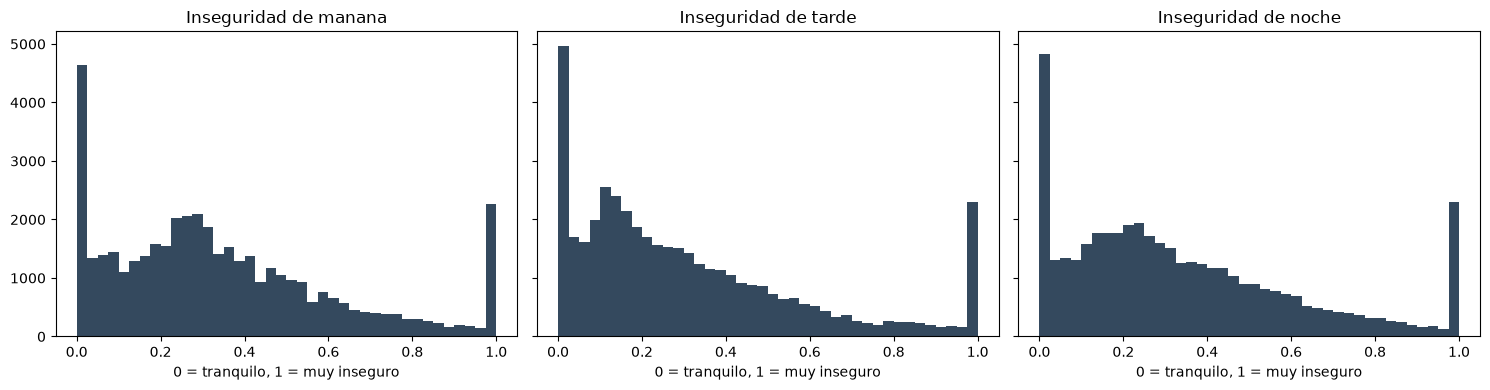

Calles que cambian más entre el día y la noche:


,nombre_via,inseguridad_manana,inseguridad_tarde,inseguridad_noche
38167,Carrera 35,0.295,0.345,1.0
18409,Carrera 79A,0.317,0.405,1.0
18410,Carrera 79A,0.317,0.405,1.0
11777,Calle 32D,0.339,0.487,1.0
11778,Calle 32D,0.339,0.487,1.0
37119,Calle 32E,0.343,0.430,1.0
37120,Calle 32E,0.343,0.430,1.0
16385,Carrera 33,0.347,0.424,1.0


In [17]:
# ¿Se nota la diferencia entre franjas? Comparamos las mismas calles a distintas horas.
fig, ejes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for eje, franja in zip(ejes, FRANJAS):
    eje.hist(aristas[f"inseguridad_{franja}"], bins=40, color="#34495e")
    eje.set_title(f"Inseguridad de {franja}")
    eje.set_xlabel("0 = tranquilo, 1 = muy inseguro")
plt.tight_layout(); plt.show()

print("Calles que cambian más entre el día y la noche:")
aristas["cambio_dia_noche"] = aristas["inseguridad_noche"] - aristas["inseguridad_manana"]
display(aristas.nlargest(8, "cambio_dia_noche")[
    ["nombre_via", "inseguridad_manana", "inseguridad_tarde", "inseguridad_noche"]].round(3))

### 7.2 Cámaras

In [18]:
arbol_camaras = cKDTree(np.c_[camaras["x"], camaras["y"]])

vecinos = arbol_camaras.query_ball_point(puntos_aristas, r=RADIO_CAMARAS)
aristas["camaras_cerca"] = np.array([len(v) for v in vecinos])
aristas["tiene_camara"] = (aristas["camaras_cerca"] > 0).astype(int)

print(f"Calles con al menos una cámara a menos de {RADIO_CAMARAS} m: "
      f"{aristas['tiene_camara'].sum():,} de {len(aristas):,} "
      f"({aristas['tiene_camara'].mean()*100:.1f}%)")

Calles con al menos una cámara a menos de 300 m: 3,584 de 43,111 (8.3%)


### 7.3 Velocidad

Si hay un sensor cerca usamos la velocidad **medida**. Si no, la velocidad teórica de OSM.
Con la velocidad y la distancia sale el tiempo: `tiempo = distancia / velocidad`.

In [19]:
arbol_sensores = cKDTree(np.c_[sensores["x"], sensores["y"]])

# Sensor más cercano a cada calle (distancia euclidiana en metros)
distancia_sensor, indice_sensor = arbol_sensores.query(puntos_aristas, k=1)

hay_sensor = distancia_sensor < RADIO_SENSORES
velocidad_sensor = sensores["velocidad_real"].values[indice_sensor]

aristas["velocidad_kmh"] = np.where(hay_sensor, velocidad_sensor, aristas["velocidad_osm"])
aristas["velocidad_kmh"] = aristas["velocidad_kmh"].clip(5, 120)
aristas["origen_velocidad"] = np.where(hay_sensor, "sensor", "osm")

# tiempo en segundos = metros / (km/h convertidos a m/s)
aristas["tiempo_s"] = aristas["distancia_m"] / (aristas["velocidad_kmh"] * 1000 / 3600)

print(aristas["origen_velocidad"].value_counts().to_string())
print(f"\nvelocidad media: {aristas['velocidad_kmh'].mean():.1f} km/h")
display(aristas[["nombre_via", "distancia_m", "velocidad_kmh", "tiempo_s", "origen_velocidad"]].head())

origen_velocidad
osm       23051
sensor    20060

velocidad media: 31.0 km/h


,nombre_via,distancia_m,velocidad_kmh,tiempo_s,origen_velocidad
0,NaN,0.682288,40.000000,0.061406,osm
1,NaN,0.843122,50.000000,0.060705,osm
2,Calle 32,1.075969,27.957841,0.138548,sensor
3,Calle 32,1.075969,27.957841,0.138548,sensor
4,Carrera 46,1.079102,30.000000,0.129492,osm


## 8. El peso de cada calle

Con toda la información pegada, definimos el costo. La idea que desarrollamos es:

> **Una calle peligrosa se siente más larga de lo que es. Una cámara hace que su peligro cuente un poco menos. Y ninguna calle se siente nunca más corta de lo que es. Ademas es una forma de tener todo en las mismas unidades**

$$
s = \text{peligro} \times (1 - 0.2 \times \text{tiene camara})
\qquad
\text{costo} = \text{distancia} \times (1 + \lambda \, s)
$$

La cámara "vuelve mas segura la calle" porque decidimos que una calle con una camara es mas segura. 

**λ** lo encontramos haciendo pruebas. 

In [20]:
# EL PESO DE CADA CALLE

# La idea en tres frases:
#   Una calle peligrosa se siente mas larga de lo que es.
#   Una camara hace que su peligro cuente un poco menos.
#   Ninguna calle se siente nunca mas corta de lo que es.

PESO_INSEGURIDAD = 6.0    # lambda: cuantos largos EXTRA se le cargan a la peor calle
                          # (el factor va de 1 a 1+lambda = 7, no a 6)
BONO_CAMARA      = 0.2    # cuanto DESCUENTA DEL PELIGRO tener una camara cerca
FACTOR_MINIMO    = 1.0    # este 1 es para que la distancia nunca sea menor que la real

for franja in FRANJAS:
    # s = peligro ya descontado por la camara
    s = aristas[f"inseguridad_{franja}"] * (1 - BONO_CAMARA * aristas["tiene_camara"])

    aristas[f"factor_{franja}"] = 1 + PESO_INSEGURIDAD * s
    aristas[f"costo_{franja}"]  = aristas["distancia_m"] * aristas[f"factor_{franja}"]

# LENTITUD: es lo mismo, pero en el eje del tiempo

# La usa la segunda heuristica. Es adimensional igual que el factor:
# cuantas veces mas lenta es esta calle que la mas rapida de la red.
# Sale >= 1 por construccion, exactamente como el factor de peligro.
VELOCIDAD_REFERENCIA = aristas["velocidad_kmh"].max()          # km/h
aristas["lentitud"] = VELOCIDAD_REFERENCIA / aristas["velocidad_kmh"]

# Comprobacion, no suposicion

# Que el factor nunca baje de 1 es lo que sostiene la heuristica admisible 
print("El factor nunca puede bajar de 1. Comprobado sobre las 43.100 calles:\n")
for franja in FRANJAS:
    f = aristas[f"factor_{franja}"]
    print(f"  {franja:8s} min {f.min():.4f}   media {f.mean():.3f}   max {f.max():.3f}"
          f"   |  aristas con factor < 1: {(f < 1).sum()}")

print("\nCosto de la misma calle en cada franja (primeras filas):")
display(aristas[["nombre_via", "distancia_m", "tiene_camara",
                 "costo_manana", "costo_tarde", "costo_noche"]].head(8).round(1))

print("\nCosto total de recorrer todas las calles de Medellin:")
for franja in FRANJAS:
    print(f"  {franja:8s} {aristas[f'costo_{franja}'].sum()/1000:>10,.0f} km equivalentes")
print(f"  {'real':8s} {aristas['distancia_m'].sum()/1000:>10,.0f} km de verdad")

El factor nunca puede bajar de 1. Comprobado sobre las 43.100 calles:

  manana   min 1.0000   media 3.026   max 7.000   |  aristas con factor < 1: 0
  tarde    min 1.0000   media 2.798   max 7.000   |  aristas con factor < 1: 0
  noche    min 1.0000   media 2.992   max 7.000   |  aristas con factor < 1: 0

Costo de la misma calle en cada franja (primeras filas):


,nombre_via,distancia_m,tiene_camara,costo_manana,costo_tarde,costo_noche
0,NaN,0.7,0,1.5,1.4,1.7
1,NaN,0.8,0,4.0,3.7,3.4
2,Calle 32,1.1,0,2.0,1.6,1.8
3,Calle 32,1.1,0,2.0,1.6,1.8
4,Carrera 46,1.1,0,3.8,3.4,4.5
5,NaN,1.1,0,2.6,2.7,2.8
6,Calle 48F,1.2,0,2.2,1.9,2.0
7,Calle 48F,1.2,0,2.2,1.9,2.0



Costo total de recorrer todas las calles de Medellin:
  manana       11,209 km equivalentes
  tarde        10,472 km equivalentes
  noche        11,060 km equivalentes
  real          4,238 km de verdad


In [40]:
aristas.head(3)

,origen,destino,distancia_m,nombre_via,tipo_via,velocidad_osm,x_medio,y_medio,distancia_recta_m,robos_manana,inseguridad_manana,robos_tarde,inseguridad_tarde,robos_noche,inseguridad_noche,cambio_dia_noche,camaras_cerca,tiene_camara,velocidad_kmh,origen_velocidad,tiempo_s,factor_manana,costo_manana,factor_tarde,costo_tarde,factor_noche,costo_noche,lentitud
0,9987035814,5510015888,0.682288,NaN,tertiary,40.0,829922.625427,1.183283e+06,0.681208,53,0.195572,57,0.178964,113,0.236897,0.041325,0,0,40.000000,osm,0.061406,2.173432,1.482905,2.073783,1.414917,2.421384,1.652080,2.000000
1,9391291818,2667852045,0.843122,NaN,secondary,50.0,833829.132807,1.186475e+06,0.843919,167,0.616236,183,0.574568,237,0.496855,-0.119381,0,0,50.000000,osm,0.060705,4.697417,3.960495,4.447410,3.749709,3.981132,3.356580,1.600000
2,3513484311,3513470678,1.075969,Calle 32,tertiary,40.0,830220.519162,1.181481e+06,1.077405,37,0.136531,28,0.087912,51,0.106918,-0.029613,0,0,27.957841,sensor,0.138548,1.819188,1.957390,1.527473,1.643513,1.641509,1.766214,2.861451


## 9. Los algoritmos de búsqueda

No usamos `networkx`, los hicimos nostros:

| Algoritmo | Prioridad | Qué mira | ¿Encuentra el óptimo? |
|---|---|---|---|
| **Costo uniforme** | $g(n)$ | Lo que ya gastó | Sí |
| **Primero el mejor** | $h(n)$ | Lo que cree que falta | No |
| **A\*** | $g(n) + h(n)$ | Ambas cosas | Sí, **si $h$ no se pasa**. osea si es admisible |

donde:

* $g(n)$ = costo acumulado desde el origen hasta $n$
* $h(n)$ = estimación de lo que falta de $n$ hasta la meta

### Las "dos heurísticas"

En realidad no hicimos, nosotros desarrollamos una pero decidimos constrastarla contra la distancia euclidiana para ver "que tan buena nos quedo". 

**La admisible.** Como ya estamos en metros y en un plano, la estimación es la distancia
euclidiana hasta la meta, que es la que hemos usasdo en clase:

$$h(n) = \sqrt{(x_n - x_{meta})^2 + (y_n - y_{meta})^2}$$

Nunca se pasa, porque la línea recta es la distancia más corta posible entre dos puntos: por la calle siempre vas a recorrer igual o más. Con esta A\* devuelve el óptimo garantizado.

**La que nosotros desarrollamos.** Se "pasa" **a propósito**: inflamos la línea recta con lo peor que
se ve dos pasos por delante. Hablando de tiempo y de seguridad. 

$$h(n) = \text{recta}(n, meta) \times \big(A \cdot \overline{\text{factor}} + B \cdot \overline{\text{lentitud}}\big)$$

donde la barra es el **promedio** de todas las calles que se ven a uno y dos pasos. La idea
es: *supongo que lo que me queda hasta la meta es una línea recta, y que toda esa
línea se parece al vecindario que veo a dos pasos de mí*.

Los dos términos del paréntesis son **adimensionales y valen ≥ 1**, y eso es lo que mantiene
`h` en metros equivalentes. Si ahí dentro se metiera `tiempo_s` en crudo, `h` quedaría en
metros·segundo y no se podría sumar con `g`. Basicamente tenemos que mantener las unidades iguales. 

Al pasarse, A\* deja de garantizar el óptimo. Y por eso queremos ver "que tanto sacrificamos" haciendo esto. 

- Una heuristica que fuera *solo* el factor de peligro no sabría dónde está la meta, con lo que no orientaría la búsqueda, por eso metimos la distancia. 
- Al inflar heuristica se "rompe" la **consistencia**, y eso importa porque los tres algoritmos meten los nodos en un `set` de visitados y no los vuelven a mirar. Ahí es donde se pierde el optimo.

In [ ]:
def construir_vecinos(tabla_aristas, columna_costo):
    # Convierte la tabla de aristas en un diccionario:
    #    {nodo: [(vecino, costo), (vecino, costo), ...]}
    # Es la forma normal de representar un grafo para recorrerlo.
    vecinos = {}
    for origen, destino, costo in zip(tabla_aristas["origen"], # zip combina las tres listas en tuplas (origen, destino, costo)
                                      tabla_aristas["destino"],
                                      tabla_aristas[columna_costo]):
        vecinos.setdefault(origen, []).append((destino, float(costo)))
    return vecinos


def reconstruir_camino(padre, inicio, meta):
    # Va del final hacia atrás siguiendo quién fue el padre de cada nodo
    if meta not in padre and meta != inicio:
        return None
    camino = [meta]
    while camino[-1] != inicio:
        camino.append(padre[camino[-1]])
    return camino[::-1]

In [ ]:
# COSTO UNIFORME 

# Siempre saca de la frontera el nodo MÁS BARATO de los pendientes.
# No sabe dónde está la meta, así que se va expandiendo en círculo
# alrededor del origen hasta tropezarse con ella.

def costo_uniforme(vecinos, inicio, meta):
    frontera = [(0.0, inicio)]      # cola de prioridad: (costo acumulado, nodo) tiene inicio porque es el primer nodo que se expande y tiene costo 0.0 
    costo_hasta = {inicio: 0.0}     # el mejor costo conocido para llegar a cada nodo
    padre = {}                      # de dónde vinimos, para reconstruir el camino
    visitados = set()               # nodos ya cerrados: no se vuelven a tocar
    expandidos = 0                  # contador, para comparar algoritmos

    while frontera:
        # heappop devuelve siempre el de menor costo acumulado
        g, nodo = heapq.heappop(frontera)

        # Puede haber copias viejas del mismo nodo en la cola (metimos una
        # entrada nueva cada vez que encontramos un camino mejor). Si ya lo
        # cerramos, esta copia es basura y se ignora.
        if nodo in visitados:
            continue

        visitados.add(nodo)
        expandidos += 1

        # Al sacar la meta de la cola tenemos la garantía de que su costo es
        # el mínimo posible: cualquier otra ruta pendiente cuesta más o igual.
        if nodo == meta:
            break

        for vecino, costo in vecinos.get(nodo, []):
            nuevo_g = g + costo                              # lo que costaría llegar por aquí

            # es mejor que el mejor camino que conocíamos hasta ese vecino?
            if nuevo_g < costo_hasta.get(vecino, float("inf")):
                costo_hasta[vecino] = nuevo_g                # nos quedamos con el nuevo
                padre[vecino] = nodo                          # y con por dónde llegamos
                heapq.heappush(frontera, (nuevo_g, vecino))   # a la cola

    return reconstruir_camino(padre, inicio, meta), expandidos, costo_hasta.get(meta)

In [ ]:
# best-first 
# Solo mira la estimación h: va siempre hacia el nodo que PARECE más
# cerca de la meta, sin importarle lo que lleva gastado.
#
# Consecuencia: es rapidísimo (abre poquísimos nodos) pero NO garantiza la mejor ruta. 
# Si se mete por una calle que apunta hacia la meta pero acaba dando una vuelta, no se entera.

def primero_el_mejor(vecinos, inicio, meta, heuristica):
    frontera = [(heuristica(inicio), inicio)]   # prioridad = SOLO lo estimado
    padre = {}
    visitados = set()
    expandidos = 0

    while frontera:
        # el guion bajo es la prioridad, que aquí no necesitamos para nada más
        _, nodo = heapq.heappop(frontera)

        if nodo in visitados:
            continue

        visitados.add(nodo)
        expandidos += 1

        if nodo == meta:
            break

        for vecino, _costo in vecinos.get(nodo, []):
            # Fíjate en que el costo NI SE MIRA (por eso se llama _costo).
            # Cada nodo se mete en la cola una sola vez y no se revisa después:
            # este algoritmo nunca se corrige a sí mismo.
            if vecino not in visitados and vecino not in padre:
                padre[vecino] = nodo
                heapq.heappush(frontera, (heuristica(vecino), vecino))

    return reconstruir_camino(padre, inicio, meta), expandidos, None

In [ ]:
# A*
# Junta los dos anteriores:  prioridad = g(n) + h(n)
#                                        |      |
#                            lo que ya gastó | lo que estima que falta

def a_estrella(vecinos, inicio, meta, heuristica):
    frontera = [(heuristica(inicio), inicio)]   # al principio g=0, así que f = h
    costo_hasta = {inicio: 0.0}                 # este es el g(n)
    padre = {}
    visitados = set()
    expandidos = 0

    while frontera:
        _, nodo = heapq.heappop(frontera)       # el de menor f = g + h

        if nodo in visitados:
            continue

        visitados.add(nodo)
        expandidos += 1

        if nodo == meta:
            break

        g = costo_hasta[nodo]                   # lo que costó llegar hasta aquí

        for vecino, costo in vecinos.get(nodo, []):
            nuevo_g = g + costo                 # lo que costaría llegar al vecino

            if nuevo_g < costo_hasta.get(vecino, float("inf")):
                costo_hasta[vecino] = nuevo_g
                padre[vecino] = nodo
                # La diferencia con costo uniforme está justo aquí: a la
                # prioridad se le SUMA la estimación de lo que queda.
                heapq.heappush(frontera, (nuevo_g + heuristica(vecino), vecino))

    return reconstruir_camino(padre, inicio, meta), expandidos, costo_hasta.get(meta)

In [ ]:
# LA HEURISTICA
# h(n) = cuanto CREEMOS que falta de n hasta la meta.
#   ADMISIBLE: h nunca se pasa del costo real que falta. A* devuelve el optimo garantizado. 
#   CON MIRADA: h se infla mirando dos niveles por delante. Se pasa a PROPOSITO. A* deja de garantizar el optimo pero abre muchisimos menos nodos. 

# Sobre el margen: proyectar a EPSG:3116 estira las distancias hasta un 0,2% de la realidad. Es muy pequeño pero igual se arregla con una multiplicación pequeña. 
MARGEN_PROYECCION = 0.998      # 0,2% de margen, por encima del 0,155% medido

# Diccionario {id_nodo: {"x":..., "y":...}} para no tocar el DataFrame dentro
# del bucle de busqueda, que seria lentisimo.
coordenadas = nodos.set_index("id_nodo")[["x", "y"]].to_dict("index")

# Heuristica de DOS NIVELES

# Estimar de forma exacta la seguridad que falta es imposible sin conocer la ruta. Lo que se hace es mirar dos pasos por delante y resumir lo quese ve:
#     desde n -> sus hijos (nivel 1) -> los hijos de sus hijos (nivel 2)
#
#   "Supongo que lo que me queda hasta la meta es una linea recta, y que
#    toda esa linea se parece al vecindario que veo a dos pasos de mi."
#
# Usamos la media de lo que vemos. 

def construir_vecinos_de(tabla_aristas, columna):
    # {nodo: [(vecino, valor_de_esa_arista), ...]}
    v = {}
    for origen, destino, valor in zip(tabla_aristas["origen"],
                                      tabla_aristas["destino"],
                                      tabla_aristas[columna]):
        v.setdefault(origen, []).append((destino, float(valor)))
    return v


def resumir_vecindario(vecinos, nodo, resumen): # Recoge las aristas a uno y dos niveles desde nodo y las resume.
    valores = []
    for hijo, valor_1 in vecinos.get(nodo, []):
        valores.append(valor_1)                       # nivel 1
        for _nieto, valor_2 in vecinos.get(hijo, []):
            valores.append(valor_2)                   # nivel 2

    if not valores:                                   # nodo sin salida
        return 1.0
    if resumen == "maximo":
        return max(valores)
    return sum(valores) / len(valores)                # media


def crear_inflador(vecinos_factor, vecinos_lentitud, A=0.5, B=0.5, resumen="media"):

    # Devuelve una funcion nodo -> cuanto inflar la linea recta.

    #     inflador(n) = A * resumen_factor_2niveles(n)
    #                 + B * resumen_lentitud_2niveles(n)

    # Los dos terminos son ADIMENSIONALES y valen >= 1, asi que la mezcla
    # tambien. Eso es lo que mantiene h en metros equivalentes: metros por
    # un numero sin unidades. Si se metiera tiempo_s en crudo aqui, h
    # quedaria en metros*segundo y no se podria sumar con g.

    #     A pesa "evitar el peligro"
    #     B pesa "evitar las calles lentas"
    #     resumen : "media" (por defecto) | "maximo"

    # Con A + B = 1 la mezcla es un promedio ponderado y se lee facil.
    # Se memoiza porque h(n) se llama muchisimas veces sobre el mismo nodo
    # y el resultado no depende de la meta ni del momento de la busqueda.
    
    memoria = {}

    def inflador(nodo):
        if nodo in memoria:
            return memoria[nodo]
        valor = (A * resumir_vecindario(vecinos_factor, nodo, resumen)
                 + B * resumir_vecindario(vecinos_lentitud, nodo, resumen))
        memoria[nodo] = valor
        return valor

    return inflador


# LA HEURISTICA

def crear_heuristica(meta, tipo="distancia", inflador=None):
    
    # Devuelve una funcion h(nodo). Se crea una por cada meta, porque la posicion del destino queda "congelada" dentro.

    # tipo     : "distancia" | "tiempo" | "seguridad"
    # inflador : None      -> heuristica ADMISIBLE (A* optimo)
    #            funcion   -> heuristica CON MIRADA (inadmisible a proposito)
    
    x_meta = coordenadas[meta]["x"]
    y_meta = coordenadas[meta]["y"]

    if tipo == "tiempo":
        # Si el costo son SEGUNDOS, la estimacion tambien tiene que estar en
        # segundos. Se divide por la velocidad mas alta de toda la red: asi
        # el tiempo estimado es el minimo imaginable y nunca nos pasamos.
        escala = 1.0 / (aristas["velocidad_kmh"].max() * 1000 / 3600)
    else:
        # Si el costo son metros, la distancia en metros vale tal cual.
        # OJO: para "seguridad" la escala es 1.0, no 0.8 como antes. Eso lo
        # permite la camara multiplicativa de la seccion 8: ahora el factor
        # minimo es 1 EXACTO, asi que cada metro cuesta al menos 1 metro
        # equivalente y no hay que rebajar nada.
        escala = 1.0

    def h(nodo):
        dx = coordenadas[nodo]["x"] - x_meta        # diferencia en metros
        dy = coordenadas[nodo]["y"] - y_meta
        base = np.sqrt(dx*dx + dy*dy) * escala * MARGEN_PROYECCION
        # Sin inflador: linea recta pura -> cota inferior -> A* optimo.
        # Con inflador: se multiplica por lo peor de alrededor.
        return base * inflador(nodo) if inflador is not None else base

    return h

# La lentitud no depende de la franja; el factor si. Aqui se deja el de noche.
vecinos_lentitud = construir_vecinos_de(aristas, "lentitud")
vecinos_factor   = construir_vecinos_de(aristas, "factor_noche")

inflador_v1 = crear_inflador(vecinos_factor, vecinos_lentitud, A=1.0, B=0.0)  # solo peligro
inflador_v2 = crear_inflador(vecinos_factor, vecinos_lentitud, A=0.5, B=0.5)  # mezcla

print("Heuristicas listas (la mirada resume el vecindario con la MEDIA):")
print("  admisible   h = recta                                  -> A* optimo")
print("  version 1   h = recta * media_factor                   -> inadmisible")
print("  version 2   h = recta * (0.5*media_factor + 0.5*media_lentitud)")

Heuristicas listas (la mirada resume el vecindario con la MEDIA):
  admisible   h = recta                                  -> A* optimo
  version 1   h = recta * media_factor                   -> inadmisible
  version 2   h = recta * (0.5*media_factor + 0.5*media_lentitud)


## 10. Buscar una ruta
Dado un punto en el mapa, encontrar el nodo más cercano; y dado
un camino, calcular cuánto mide, cuánto tarda y qué tan inseguro es.

In [26]:
# Árbol de nodos para encontrar el más cercano a un punto cualquiera
arbol_nodos = cKDTree(nodos[["x", "y"]].values)

LUGARES = {
    "Parque Berrío":        (6.25060, -75.56820),
    "Parque de El Poblado": (6.20940, -75.56760),
    "Estadio":              (6.25640, -75.59000),
    "Universidad de Antioquia": (6.26760, -75.56880),
    "San Javier":           (6.25580, -75.61680),
    "Terminal del Norte":   (6.27950, -75.56770),
    "Centro Comercial Santafé": (6.19750, -75.57450),
    "Aeropuerto Olaya Herrera": (6.21990, -75.59060),
}

def buscar_nodo(lugar):
    # Acepta un nombre de LUGARES o una tupla (lat, lon)
    lat, lon = LUGARES[lugar] if isinstance(lugar, str) else lugar
    x, y = a_metros.transform(lon, lat)          # a metros, que es donde vive el árbol
    _, indice = arbol_nodos.query([x, y], k=1)
    return int(nodos.iloc[indice]["id_nodo"])


# Diccionario para buscar los datos de una calle rápido: (origen, destino) -> fila
datos_arista = aristas.set_index(["origen", "destino"])

def resumir_camino(camino, franja):
    # Recorre el camino sumando distancia y tiempo, y promediando la inseguridad
    tramos = list(zip(camino[:-1], camino[1:]))
    filas = datos_arista.loc[tramos]

    distancia = filas["distancia_m"].sum()
    return {
        "tramos": len(tramos),
        "distancia_km": round(distancia / 1000, 2),
        "tiempo_min": round(filas["tiempo_s"].sum() / 60, 1),
        # promedio ponderado: una calle larga pesa más que una corta
        "inseguridad_media": round(
            np.average(filas[f"inseguridad_{franja}"], weights=filas["distancia_m"]), 3),
        "calles_con_camara": int(filas["tiene_camara"].sum()),
        "robos_cerca": int(filas[f"robos_{franja}"].sum()),
    }

## 11. Comparamos tres rutas

Ahora sí: mismo origen, mismo destino, tres formas de decidir.
- **Más corta**  metros 
- **Más rápida**  segundos 
- **Más segura** metros castigados por inseguridad 

In [ ]:
# EL PAR QUE SE VA A PROBAR
# Todos estos pares se arman con los lugares que YA están en LUGARES
# (28 con ocho lugares, 36 con nueve). 
#
# También podemos usar una tupla (lat, lon) para un sitio que no esté en la lista,
# porque buscar_nodo() acepta las dos cosas. La UPB está puesta así.
PARES = {
    # el par de referencia
    "occidente-sur":      ("San Javier", "Parque de El Poblado"),

    # el más largo de todos: atraviesa la ciudad entera de norte a sur, y es
    # el que más nodos hace expandir a los tres algoritmos
    "norte-sur":          ("Terminal del Norte", "Centro Comercial Santafé"),

    # obliga a pasar por el centro, que es la zona con más robos de toda la
    # ciudad (aquí es donde más se nota el castigo por inseguridad)
    "centro-occidente":   ("Universidad de Antioquia", "San Javier"),

    # corto y céntrico: sirve para ver qué hace el algoritmo cuando casi no
    # hay margen para desviarse
    "centro-corto":       ("Parque Berrío", "Aeropuerto Olaya Herrera"),

    # dos puntos de la zona buena de la ciudad(la ruta segura y la corta deberían parecerse mucho)
    "estadio-poblado":    ("Estadio", "Parque de El Poblado"),

    # un origen que no está en LUGARES 
    "upb-poblado":        ((6.24212, -75.58902), "Parque de El Poblado"),
}

# Aviso: ORIGEN y DESTINO arrastran a las secciones 12, 13 y 15 enteras, y
# los resultados que cita la sección 16 son los de "occidente-sur". Si lo
# cambias, esos números dejan de corresponder con lo que sale abajo.
PAR = "norte-sur" #Definimos el par a probar 

ORIGEN, DESTINO = PARES[PAR]
FRANJA_ACTUAL = "noche"          # cambiar a "manana" o "tarde" para comparar

nodo_inicio = buscar_nodo(ORIGEN)
nodo_meta = buscar_nodo(DESTINO)

print(f"De: {ORIGEN}  (nodo {nodo_inicio})")
print(f"A:  {DESTINO} (nodo {nodo_meta})")

# Distancia en línea recta, para tener una referencia
x1, y1 = coordenadas[nodo_inicio]["x"], coordenadas[nodo_inicio]["y"]
x2, y2 = coordenadas[nodo_meta]["x"], coordenadas[nodo_meta]["y"]
print(f"En línea recta: {np.sqrt((x2-x1)**2 + (y2-y1)**2)/1000:.2f} km")

De: Terminal del Norte  (nodo 6597638075)
A:  Centro Comercial Santafé (nodo 9413767156)
En línea recta: 9.12 km


In [ ]:
CONFIGURACIONES = {
    "Más corta":  ("distancia_m",            "distancia"),
    "Más rápida": ("tiempo_s",               "tiempo"),
    "Más segura": (f"costo_{FRANJA_ACTUAL}", "seguridad"), # costo_noche, costo_tarde, costo_manana
}

rutas = {}
resumenes = []

for nombre, (columna_costo, tipo_heuristica) in CONFIGURACIONES.items():
    vecinos = construir_vecinos(aristas, columna_costo)
    heuristica = crear_heuristica(nodo_meta, tipo_heuristica)

    camino, expandidos, _ = a_estrella(vecinos, nodo_inicio, nodo_meta, heuristica)

    rutas[nombre] = camino
    resumen = resumir_camino(camino, FRANJA_ACTUAL)
    resumen["ruta"] = nombre
    resumen["nodos_expandidos"] = expandidos
    resumenes.append(resumen)

tabla = pd.DataFrame(resumenes).set_index("ruta")
print(f"Franja: {FRANJA_ACTUAL}\n")
display(tabla)

Franja: noche



,tramos,distancia_km,tiempo_min,inseguridad_media,calles_con_camara,robos_cerca,nodos_expandidos
ruta,,,,,,,
Más corta,103,10.65,22.7,0.736,20,60664,3111
Más rápida,90,12.01,19.6,0.476,7,20348,12327
Más segura,62,12.53,22.1,0.354,9,11538,14961


### 11.1 ¿Cuánto hay que castigar para que la ruta cambie?

Probamos varios valores de $\lambda$ (`PESO_INSEGURIDAD`) y se mira si la ruta se mueve.


In [41]:
pruebas = []
for peso in [0, 1, 2, 3, 4, 6, 8, 12]:
    s = aristas["inseguridad_noche"] * (1 - BONO_CAMARA * aristas["tiene_camara"])
    aristas["costo_prueba"] = aristas["distancia_m"] * (1 + peso * s)

    vecinos_prueba = construir_vecinos(aristas, "costo_prueba")
    heuristica_prueba = crear_heuristica(buscar_nodo("Parque de El Poblado"), "seguridad")
    camino_prueba, _, _ = a_estrella(vecinos_prueba,
                                     buscar_nodo("San Javier"),
                                     buscar_nodo("Parque de El Poblado"),
                                     heuristica_prueba)
    r = resumir_camino(camino_prueba, "noche")
    r["lambda"] = peso
    pruebas.append(r)

aristas.drop(columns=["costo_prueba"], inplace=True)
tabla_pruebas = pd.DataFrame(pruebas).set_index("lambda")
display(tabla_pruebas[["distancia_km", "tiempo_min", "inseguridad_media", "calles_con_camara"]])

,distancia_km,tiempo_min,inseguridad_media,calles_con_camara
lambda,,,,
0,9.03,21.8,0.569,43
1,9.03,21.8,0.568,42
2,9.03,21.8,0.568,42
3,9.08,22.3,0.562,42
4,9.08,22.3,0.562,42
6,11.37,22.8,0.392,28
8,11.37,22.8,0.392,28
12,11.37,22.8,0.392,28



Con lambda de 0 a 4 la ruta practicamente no cambia (no le compensa desviarse) A partir de 6 si cambia, y baja la inseguridad a costa de mas kilometros.Por eso tomamos lambda 6. 

## 12. Comparar los tres algoritmos

Misma ruta, mismo costo, tres formas de buscarla. Queremos ver cuantos nodos se despliegan y si encuentran la ruta optima que costo uniforme la devuelve. 

In [30]:
columna = f"costo_{FRANJA_ACTUAL}"
vecinos = construir_vecinos(aristas, columna)
heuristica = crear_heuristica(nodo_meta, "seguridad")

resultados = []

camino, expandidos, costo = costo_uniforme(vecinos, nodo_inicio, nodo_meta)
resultados.append({"algoritmo": "Costo uniforme", "nodos_expandidos": expandidos,
                   "costo_total": round(costo, 1), "tramos": len(camino) - 1})

camino_bf, expandidos_bf, _ = primero_el_mejor(vecinos, nodo_inicio, nodo_meta, heuristica)
costo_bf = sum(datos_arista.loc[(a, b), columna]
               for a, b in zip(camino_bf[:-1], camino_bf[1:]))
resultados.append({"algoritmo": "Primero el mejor", "nodos_expandidos": expandidos_bf,
                   "costo_total": round(costo_bf, 1), "tramos": len(camino_bf) - 1})

camino_a, expandidos_a, costo_a = a_estrella(vecinos, nodo_inicio, nodo_meta, heuristica)
resultados.append({"algoritmo": "A*", "nodos_expandidos": expandidos_a,
                   "costo_total": round(costo_a, 1), "tramos": len(camino_a) - 1})

comparacion = pd.DataFrame(resultados).set_index("algoritmo")
display(comparacion)

optimo = comparacion["costo_total"].min()
print(f"\nCosto óptimo: {optimo:,.0f}")
print(f"A* expandió un {(1 - expandidos_a/expandidos)*100:.0f}% menos de nodos que costo uniforme,")
print(f"y llegó al mismo resultado: {abs(costo_a - costo) < 0.01}")
print(f"\nPrimero el mejor abrió solo {expandidos_bf:,} nodos (el que menos),")
print(f"pero su ruta cuesta un {(costo_bf/optimo - 1)*100:.1f}% más que la óptima.")
print("Eso es exactamente lo que se espera: es el más rápido pero no garantiza nada.")

,nodos_expandidos,costo_total,tramos
algoritmo,,,
Costo uniforme,16306,38212.3,62
Primero el mejor,208,54602.9,127
A*,14961,38212.3,62



Costo óptimo: 38,212
A* expandió un 8% menos de nodos que costo uniforme,
y llegó al mismo resultado: True

Primero el mejor abrió solo 208 nodos (el que menos),
pero su ruta cuesta un 42.9% más que la óptima.
Eso es exactamente lo que se espera: es el más rápido pero no garantiza nada.


### 12.1 Qué cuesta renunciar a la admisibilidad

La heurística de nosotros **se pasa a propósito**, así que A\* deja de garantizar la ruta
óptima. Por eso usamos costo optimo para ver que tanto "perdemos". 

Y tambien decidimos comparar dos versiones de nuestra heuristica pero igual nos quedamos con una, la diferencia es la "lentitud" que se calcula igual que la seguridad pero con tiempo:

$$
\text{v1:}\; h = \text{recta} \times \text{peor factor}
\qquad
\text{v2:}\; h = \text{recta} \times (A \cdot \text{peor factor} + B \cdot \text{peor lentitud})
$$

Los dos términos de la mezcla son **adimensionales y valen ≥ 1**, y eso es lo que mantiene
`h` en metros equivalentes. Si metieramos `tiempo_s` en crudo dentro del paréntesis dejaría `h` en
metros·segundo, que no se puede sumar con `g` por eso en la heuristica tambien nos toco meter 
una e.

In [42]:
# Todas usan el mismo costo (distancia x factor). Lo unico que
# cambia es la heuristica. Costo uniforme da el optimo de referencia.

import itertools

vecinos_seg    = construir_vecinos(aristas, f"costo_{FRANJA_ACTUAL}")
vecinos_factor = construir_vecinos_de(aristas, f"factor_{FRANJA_ACTUAL}")
pares = list(itertools.combinations(LUGARES.keys(), 2))

def costo_de(camino):
    tramos = list(zip(camino[:-1], camino[1:]))
    return datos_arista.loc[tramos, f"costo_{FRANJA_ACTUAL}"].sum()

# referencia optima, una sola vez por ruta
referencia = []
for a, b in pares:
    ini, fin = buscar_nodo(a), buscar_nodo(b)
    if ini == fin:
        continue
    _, exp, optimo = costo_uniforme(vecinos_seg, ini, fin)
    if optimo is not None:
        referencia.append((ini, fin, optimo, exp))

# (etiqueta, A, B, resumen).  A=None -> heuristica admisible.
CANDIDATAS = [
    ("admisible  (recta sola)",   None, None, None),
    ("maximo  A=1.0 B=0.0",        1.0,  0.0, "maximo"),
    ("maximo  A=0.5 B=0.5",        0.5,  0.5, "maximo"),
    ("maximo  A=0.3 B=0.7",        0.3,  0.7, "maximo"),
    ("media   A=1.0 B=0.0",        1.0,  0.0, "media"),
    ("media   A=0.5 B=0.5",        0.5,  0.5, "media"),
    ("media   A=0.3 B=0.7",        0.3,  0.7, "media"),
    ("media   A=0.0 B=1.0",        0.0,  1.0, "media"),
]

filas = [{"heuristica": "costo uniforme (optimo)",
          "nodos_expandidos": round(np.mean([r[3] for r in referencia])),
          "sobrecosto_medio_%": 0.0, "peor_ruta_%": 0.0,
          "rutas_optimas": f"{len(referencia)}/{len(referencia)}"}]

for etiqueta, A, B, resumen in CANDIDATAS:
    expandidos, sobrecostos = [], []
    for ini, fin, optimo, _ in referencia:
        inf = (None if A is None else
               crear_inflador(vecinos_factor, vecinos_lentitud, A, B, resumen))
        h = crear_heuristica(fin, "seguridad", inflador=inf)
        camino, exp, _ = a_estrella(vecinos_seg, ini, fin, h)
        expandidos.append(exp)
        sobrecostos.append((costo_de(camino) / optimo - 1) * 100)
    sobrecostos = np.array(sobrecostos)
    filas.append({"heuristica": etiqueta,
                  "nodos_expandidos": round(np.mean(expandidos)),
                  "sobrecosto_medio_%": round(sobrecostos.mean(), 2),
                  "peor_ruta_%": round(sobrecostos.max(), 2),
                  "rutas_optimas": f"{int((sobrecostos < 1e-6).sum())}/{len(sobrecostos)}"})

tabla_heuristicas = pd.DataFrame(filas).set_index("heuristica")
base_nodos = tabla_heuristicas.loc["costo uniforme (optimo)", "nodos_expandidos"]
tabla_heuristicas["ahorro_nodos_%"] = (
    100 * (1 - tabla_heuristicas["nodos_expandidos"] / base_nodos)).round(1)
display(tabla_heuristicas)

print(f"Promedio sobre {len(referencia)} rutas entre los lugares de LUGARES.\n")

,nodos_expandidos,sobrecosto_medio_%,peor_ruta_%,rutas_optimas,ahorro_nodos_%
heuristica,,,,,
costo uniforme (optimo),8724,0.00,0.00,28/28,0.0
admisible (recta sola),6177,-0.00,0.00,28/28,29.2
maximo A=1.0 B=0.0,1457,11.38,41.12,6/28,83.3
maximo A=0.5 B=0.5,1615,6.01,20.55,9/28,81.5
maximo A=0.3 B=0.7,1803,3.49,14.99,8/28,79.3
media A=1.0 B=0.0,1511,7.94,29.26,6/28,82.7
media A=0.5 B=0.5,1775,3.13,10.54,9/28,79.7
media A=0.3 B=0.7,2101,3.28,13.11,11/28,75.9
media A=0.0 B=1.0,2511,3.95,20.53,8/28,71.2


Promedio sobre 28 rutas entre los lugares de LUGARES.



- La admisible no se equivoca NUNCA, pero solo ahorra un ~29% de nodos.
- Inflar h ahorra un ~80% de nodos a cambio de perder el optimo.
- MEDIA gana a MAXIMO en todas las combinaciones, y sobre todo baja el PEOR caso (de 41% a 29% con A=1, de 15% a 11% con la mezcla).
- El maximo salta de 1 a 7 entre nodos vecinos; la media se mueve mucho menos, asi que rompe la consistencia con menos violencia.
- El elegido es media con A=0.5 B=0.5: ~3.2% de sobrecosto, ~80% de ahorro, y pesos iguales, que es lo mas facil de defender.

## 13. La misma ruta a distintas horas

Aquí se ve si lo que hicimos de separar por franjas sirvió de algo la ruta "más segura" debería cambiar entre la mañana y la noche al menos

In [ ]:
rutas_por_franja = {}
filas = []

for franja in FRANJAS:
    vecinos = construir_vecinos(aristas, f"costo_{franja}")
    heuristica = crear_heuristica(nodo_meta, "seguridad")
    camino, _, _ = a_estrella(vecinos, nodo_inicio, nodo_meta, heuristica)

    rutas_por_franja[franja] = camino
    resumen = resumir_camino(camino, franja)
    resumen["franja"] = franja
    filas.append(resumen)

display(pd.DataFrame(filas).set_index("franja"))

# son rutas distintas o la misma?
print("\n¿Cambia la ruta según la hora?")
for a in FRANJAS:
    for b in FRANJAS:
        if a < b:
            iguales = rutas_por_franja[a] == rutas_por_franja[b]
            print(f"  {a} vs {b}: {'misma ruta' if iguales else 'RUTAS DISTINTAS'}")

,tramos,distancia_km,tiempo_min,inseguridad_media,calles_con_camara,robos_cerca
franja,,,,,,
manana,139,14.79,29.5,0.363,26,16361
tarde,167,16.27,29.0,0.253,2,15197
noche,62,12.53,22.1,0.354,9,11538



¿Cambia la ruta según la hora?
  manana vs tarde: RUTAS DISTINTAS
  manana vs noche: RUTAS DISTINTAS
  noche vs tarde: RUTAS DISTINTAS


## 14. Todo junto en una función

Para no tener que reejecutar el análisis cada vez que se quiere probar un par de puntos.

In [ ]:
def buscar_ruta(origen, destino, franja="noche", criterio="seguridad",
                algoritmo="a_estrella", heuristica="admisible"):
    # criterio   : "distancia" | "tiempo" | "seguridad"
    # algoritmo  : "a_estrella" | "costo_uniforme" | "primero_el_mejor"
    # heuristica : "admisible" -> linea recta, A* devuelve el optimo
    #              "v1"        -> recta * media_factor           (inadmisible)
    #              "v2"        -> recta * (0.5*factor + 0.5*lentitud)
    #              Los numeros de cada una estan medidos en la seccion 12.1.
    columnas = {"distancia": "distancia_m",
                "tiempo": "tiempo_s",
                "seguridad": f"costo_{franja}"}
    columna = columnas[criterio]

    nodo_a = buscar_nodo(origen)
    nodo_b = buscar_nodo(destino)

    # El inflador se construye con el factor de LA FRANJA PEDIDA, no con el
    # de noche que quedo fijado en la seccion 10.
    if heuristica == "admisible":
        inflador = None
    else:
        A, B = (1.0, 0.0) if heuristica == "v1" else (0.5, 0.5)
        inflador = crear_inflador(construir_vecinos_de(aristas, f"factor_{franja}"),
                                  vecinos_lentitud, A=A, B=B)

    vecinos = construir_vecinos(aristas, columna)
    funcion_h = crear_heuristica(nodo_b, criterio, inflador=inflador)

    if algoritmo == "costo_uniforme":
        camino, expandidos, _ = costo_uniforme(vecinos, nodo_a, nodo_b)
    elif algoritmo == "primero_el_mejor":
        camino, expandidos, _ = primero_el_mejor(vecinos, nodo_a, nodo_b, funcion_h)
    else:
        camino, expandidos, _ = a_estrella(vecinos, nodo_a, nodo_b, funcion_h)

    resumen = resumir_camino(camino, franja)
    resumen["nodos_expandidos"] = expandidos
    print(f"{origen} -> {destino}  ({criterio}, {franja}, {algoritmo}, h={heuristica})")
    print(pd.Series(resumen).to_string())

    return camino, resumen


camino, resumen = buscar_ruta("Universidad de Antioquia", "Centro Comercial Santafé",
                              franja="noche", criterio="seguridad")

Universidad de Antioquia -> Centro Comercial Santafé  (seguridad, noche, a_estrella, h=admisible)
tramos                  79.000
distancia_km            10.460
tiempo_min              18.300
inseguridad_media        0.415
calles_con_camara        9.000
robos_cerca          15953.000
nodos_expandidos     13339.000


## 15. Ver las rutas en el mapa

Hasta aquí las rutas son listas de números. Aca los pintamos

Ese es todo el argumento. Los caminos que devuelven `costo_uniforme`, `primero_el_mejor` y
`a_estrella` son listas de `id_nodo`, y esos id son los de OpenStreetMap: exactamente las
claves de `grafo_grados`, porque la tabla `aristas` se construyó a partir de él en la
sección 6. Así que se le pasan a `osmnx` tal cual y ya está. No hay grafo serializado a
JSON, no hay índices propios que reconciliar, no hay una segunda implementación de A\* en
otro lenguaje. Lo que se dibuja es literalmente lo que calcularon los algoritmos.

Todo lo de aquí abajo **solo lee**: no toca costos, ni heurísticas, ni la tabla de aristas.
Y cuelga de una sola cosa, `buscar_ruta()` (sección 14), así que funciona aunque no hayas
ejecutado las celdas de las secciones 11 y 13.

Se dibuja sobre `grafo_grados` (latitud/longitud) y no sobre `grafo` (metros): las dos
versiones tienen los mismos nodos y los mismos id, pero en grados los ejes son los que
uno reconoce en cualquier mapa. Es también lo que hace el notebook de referencia.

In [34]:
# HERRAMIENTAS DE DIBUJO
from matplotlib.collections import LineCollection

COLOR_FONDO = "#111111"
COLOR_CALLES = "#4a4a4a"

# Paleta pensada para que se distingan sobre fondo oscuro y sigan
# distinguiéndose impresas en gris.
PALETA = ["#e8543f",   # rojo naranja
          "#4a9de0",   # azul
          "#f2c14e"]   # amarillo


def comprobar_camino(camino):
    # Antes de dibujar, comprobar que el camino se puede dibujar.
    # Puede fallar por una razón concreta: la tabla `aristas` se quedó con la
    # más corta de cada par origen-destino (sección 6), así que es un
    # SUBCONJUNTO de las aristas del grafo. Al revés no puede pasar, pero se
    # verifica en vez de suponerlo.
    faltan = [(u, v) for u, v in zip(camino[:-1], camino[1:])
              if not grafo_grados.has_edge(u, v)]
    if faltan:
        print(f"AVISO: {len(faltan)} tramos del camino no están en el grafo: {faltan[:3]}")
    return not faltan


def recortar_grafo(caminos, margen=0.25):
    """
    Devuelve el trozo de grafo que rodea a los caminos.

    Dibujar Medellín entera son 18.314 nodos y 43.100 aristas: tarda, y la
    ruta queda como un hilo sobre una maraña gris. Recortar a la caja de la
    ruta con un margen la hace legible. Para la figura del informe, donde SÍ
    interesa ver dónde cae la ruta dentro de la ciudad, se pasa recortar=False.
    """
    lats = [grafo_grados.nodes[n]["y"] for c in caminos for n in c]
    lons = [grafo_grados.nodes[n]["x"] for c in caminos for n in c]

    # El máximo con 0.004 evita que una ruta muy corta genere una caja
    # degenerada de la que osmnx no pueda sacar límites.
    alto  = max(max(lats) - min(lats), 0.004)
    ancho = max(max(lons) - min(lons), 0.004)

    # osmnx 2.x espera la caja como (izquierda, abajo, derecha, arriba).
    caja = (min(lons) - ancho*margen, min(lats) - alto*margen,
            max(lons) + ancho*margen, max(lats) + alto*margen)

    # truncate_by_edge=True conserva los nodos justo fuera de la caja que
    # siguen conectados hacia dentro, para que las calles no queden cortadas
    # a media manzana en el borde.
    return ox.truncate.truncate_graph_bbox(grafo_grados, caja, truncate_by_edge=True)


def dibujar_rutas(caminos, etiquetas, colores=None, titulo="", recortar=True,
                  margen=0.25, figsize=(12, 12), ax=None, archivo=None):
    """
    Dibuja una o varias rutas sobre el mapa de calles.

    recortar : True recorta a la caja de la ruta; False dibuja el municipio
               entero, corregimientos incluidos (y la ruta sale diminuta).
    archivo  : nombre dentro de CARPETA_SALIDA, o None para no guardar.
    """
    caminos = list(caminos)
    colores = list(colores) if colores else PALETA[:len(caminos)]
    for c in caminos:
        comprobar_camino(c)

    g = recortar_grafo(caminos, margen) if recortar else grafo_grados

    propio = ax is None
    if propio:
        fig, ax = plt.subplots(figsize=figsize, facecolor=COLOR_FONDO)
    else:
        fig = ax.figure
    ax.set_facecolor(COLOR_FONDO)

    # TRAMPA PAGADA: si a plot_graph_route (y por tanto a plot_graph_routes)
    # se le pasa un `ax`, NO dibuja el grafo: da por hecho que ya está pintado
    # y solo añade la ruta encima. Por eso el mapa de calles va primero y en
    # una llamada aparte. Sin esta línea las rutas salen flotando en el vacío.
    ox.plot_graph(g, ax=ax, node_size=0, edge_color=COLOR_CALLES,
                  edge_linewidth=0.5, bgcolor=COLOR_FONDO, show=False, close=False)

    ox.plot_graph_routes(g, caminos,
                         route_colors=colores,
                         route_linewidths=[4] * len(caminos),
                         route_alpha=0.95,       # el 0.5 por defecto las deslava
                         orig_dest_size=90,      # los puntos de origen y destino
                         ax=ax, show=False, close=False)

    ax.legend(handles=[plt.Line2D([0], [0], color=c, lw=3, label=e)
                       for c, e in zip(colores, etiquetas)],
              loc="upper right", facecolor=COLOR_FONDO, framealpha=0.9,
              edgecolor="#555555", labelcolor="w", fontsize=11)

    if titulo:
        ax.set_title(titulo, color="w", fontsize=14, pad=12)

    if archivo:
        fig.savefig(CARPETA_SALIDA / archivo, dpi=200,
                    facecolor=COLOR_FONDO, bbox_inches="tight")
        print(f"guardado: {CARPETA_SALIDA / archivo}")

    return fig, ax


def tabla_en_eje(ax, tabla):
    # Pinta un DataFrame como tabla dentro de un eje, en el estilo oscuro del
    # mapa. Es para la figura del informe: mapa y números en una sola imagen.
    ax.set_facecolor(COLOR_FONDO)
    ax.axis("off")
    t = ax.table(cellText=tabla.astype(str).values,
                 colLabels=tabla.columns, rowLabels=tabla.index,
                 loc="center", cellLoc="center")
    t.auto_set_font_size(False)
    t.set_fontsize(11)
    t.scale(1, 1.9)
    for celda in t.get_celld().values():
        celda.set_edgecolor("#555555")
        celda.set_facecolor(COLOR_FONDO)
        celda.set_text_props(color="w")
    return t


def mapa_inseguridad(camino, franja, titulo="", archivo=None, figsize=(12, 12)):
    """
    Pinta la ruta coloreada tramo a tramo por su inseguridad.

    Es la única vista que no sale de plot_graph_route, porque esa función
    pinta la ruta entera de un color. Aquí se dibuja el mapa por un lado y
    encima va una LineCollection: un montón de segmentos, cada uno con su
    color. Devuelve también la tabla de los peores tramos.
    """
    tramos = list(zip(camino[:-1], camino[1:]))
    datos_tramos = datos_arista.loc[tramos]
    inseguridad = datos_tramos[f"inseguridad_{franja}"].values

    # Cada segmento es [(lon_origen, lat_origen), (lon_destino, lat_destino)].
    # Ojo al orden: matplotlib quiere (x, y), y aquí la x es la LONGITUD.
    segmentos = [[(grafo_grados.nodes[u]["x"], grafo_grados.nodes[u]["y"]),
                  (grafo_grados.nodes[v]["x"], grafo_grados.nodes[v]["y"])]
                 for u, v in tramos]

    fig, ax = plt.subplots(figsize=figsize, facecolor=COLOR_FONDO)
    ax.set_facecolor(COLOR_FONDO)
    ox.plot_graph(recortar_grafo([camino]), ax=ax, node_size=0,
                  edge_color=COLOR_CALLES, edge_linewidth=0.5,
                  bgcolor=COLOR_FONDO, show=False, close=False)

    lineas = LineCollection(segmentos, cmap="RdYlGn_r", linewidths=4.5, zorder=3)
    lineas.set_array(inseguridad)
    lineas.set_clim(0, 1)      # escala fija 0-1: así dos figuras se comparan
    ax.add_collection(lineas)

    barra = fig.colorbar(lineas, ax=ax, shrink=0.6, pad=0.01)
    barra.set_label(f"inseguridad ({franja})", color="w", fontsize=11)
    barra.ax.tick_params(colors="w")
    if titulo:
        ax.set_title(titulo, color="w", fontsize=14, pad=12)

    if archivo:
        fig.savefig(CARPETA_SALIDA / archivo, dpi=200,
                    facecolor=COLOR_FONDO, bbox_inches="tight")
        print(f"guardado: {CARPETA_SALIDA / archivo}")

    peores = (datos_tramos.assign(inseguridad=inseguridad)
              .sort_values("inseguridad", ascending=False)
              .head(5)[["nombre_via", "distancia_m", "inseguridad", "tiene_camara"]])
    return fig, peores


def comparar_franjas(origen, destino, etiqueta="", archivo=None, margen=0.25):
    """
    La ruta más segura de cada franja para un par de puntos cualquiera.

    origen y destino pueden ser un nombre de LUGARES o una tupla (lat, lon),
    porque buscar_nodo() acepta las dos cosas.
    """
    caminos, filas = [], []
    for franja in FRANJAS:
        camino, resumen = ruta_silenciosa(origen, destino,
                                          franja=franja, criterio="seguridad")
        caminos.append(camino)
        resumen["franja"] = franja
        filas.append(resumen)

    tabla = pd.DataFrame(filas).set_index("franja")[
        ["distancia_km", "tiempo_min", "inseguridad_media", "robos_cerca"]]
    display(tabla)

    # ¿De verdad son rutas distintas, o el mapa engaña?
    nombres = list(FRANJAS)
    for k, a in enumerate(nombres):
        for b in nombres[k+1:]:
            iguales = caminos[k] == caminos[nombres.index(b)]
            print(f"  {a} vs {b}: {'MISMA ruta' if iguales else 'rutas distintas'}")

    dibujar_rutas(caminos, etiquetas=nombres, margen=margen,
                  titulo=f"{etiqueta}: la ruta más segura de cada franja",
                  archivo=archivo)
    plt.show()
    return caminos, tabla


def ruta_silenciosa(origen, destino, **kwargs):
    # buscar_ruta() imprime su propio resumen, y aquí se llama varias veces
    # seguidas. Se silencia la impresión y se muestra una tabla junta al final.
    import io, contextlib
    with contextlib.redirect_stdout(io.StringIO()):
        return buscar_ruta(origen, destino, **kwargs)


print("Listo. Se dibuja sobre grafo_grados:",
      f"{grafo_grados.number_of_nodes():,} nodos, {grafo_grados.number_of_edges():,} aristas")

Listo. Se dibuja sobre grafo_grados: 18,316 nodos, 43,297 aristas


### 15.1 Tres formas de llegar al mismo sitio

Las tres rutas de la la más corta, la más rápida y la más segura sobre el
mismo mapa. La tabla dice en qué se diferencian; el mapa nos deja ver **por dónde** se diferencian.

,distancia_km,tiempo_min,inseguridad_media,calles_con_camara
ruta,,,,
Más corta,10.65,22.7,0.736,20
Más rápida,12.01,19.6,0.476,7
Más segura,12.53,22.1,0.354,9


guardado: salidas\rutas_criterios.png


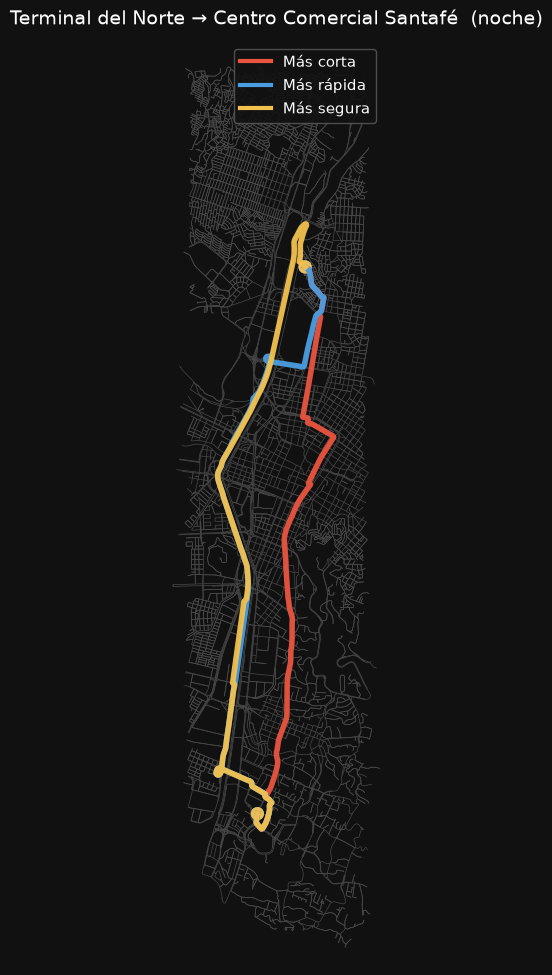

In [35]:
CRITERIOS = [("Más corta",  "distancia"),
             ("Más rápida", "tiempo"),
             ("Más segura", "seguridad")]

caminos_criterio, filas = [], []
for etiqueta, criterio in CRITERIOS:
    camino, resumen = ruta_silenciosa(ORIGEN, DESTINO,
                                      franja=FRANJA_ACTUAL, criterio=criterio)
    caminos_criterio.append(camino)
    resumen["ruta"] = etiqueta
    filas.append(resumen)

tabla_criterios = pd.DataFrame(filas).set_index("ruta")[
    ["distancia_km", "tiempo_min", "inseguridad_media", "calles_con_camara"]]
display(tabla_criterios)

dibujar_rutas(caminos_criterio,
              etiquetas=[e for e, _ in CRITERIOS],
              titulo=f"{ORIGEN} → {DESTINO}  ({FRANJA_ACTUAL})",
              archivo="rutas_criterios.png")
plt.show()

### 15.2 La misma ruta a distintas horas

Esta es la figura que cuenta el proyecto. Mismo origen, mismo destino, mismo algoritmo:
lo único que cambia es la franja horaria, y con ella la columna de costo. Si las tres
líneas se separan, separar los robos por franja sirvió de algo.

,distancia_km,tiempo_min,inseguridad_media,robos_cerca
franja,,,,
manana,14.79,29.5,0.363,16361
tarde,16.27,29.0,0.253,15197
noche,12.53,22.1,0.354,11538


  manana vs tarde: rutas distintas
  manana vs noche: rutas distintas
  tarde vs noche: rutas distintas
guardado: salidas\rutas_franjas.png


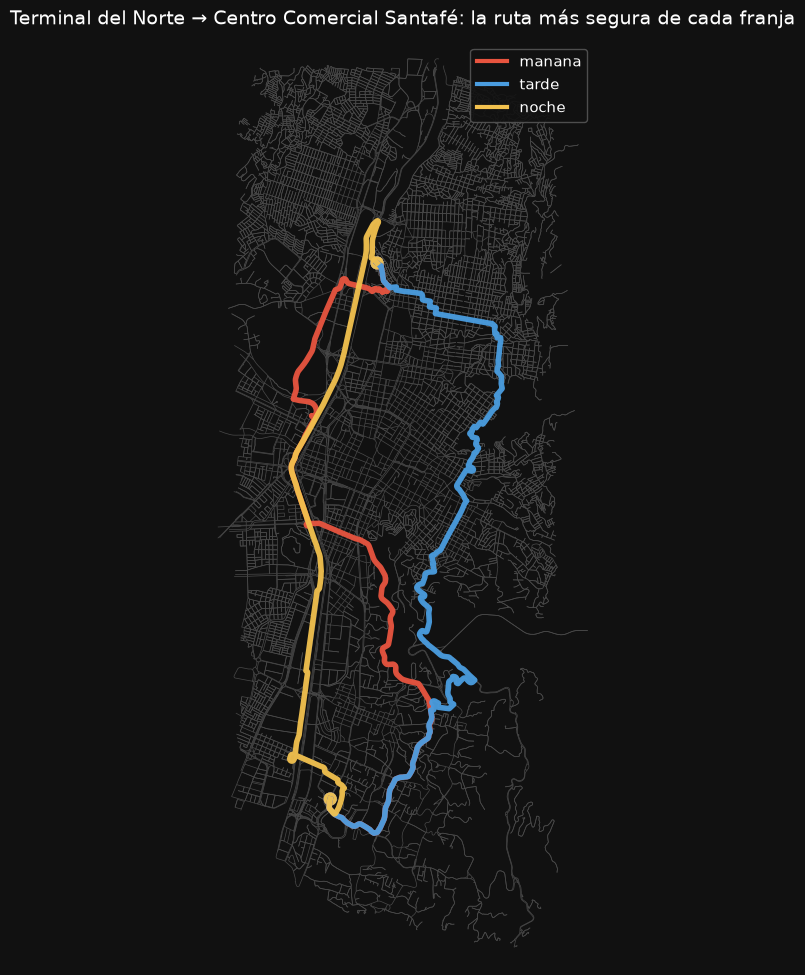

In [36]:
caminos_franja, tabla_franjas = comparar_franjas(
    ORIGEN, DESTINO,
    etiqueta=f"{ORIGEN} → {DESTINO}",
    archivo="rutas_franjas.png")

### 15.3 La figura para el informe

La misma comparación por franjas, pero sobre **la ciudad entera** y con la tabla al lado,
en una sola imagen.

guardado: salidas\figura_informe.png


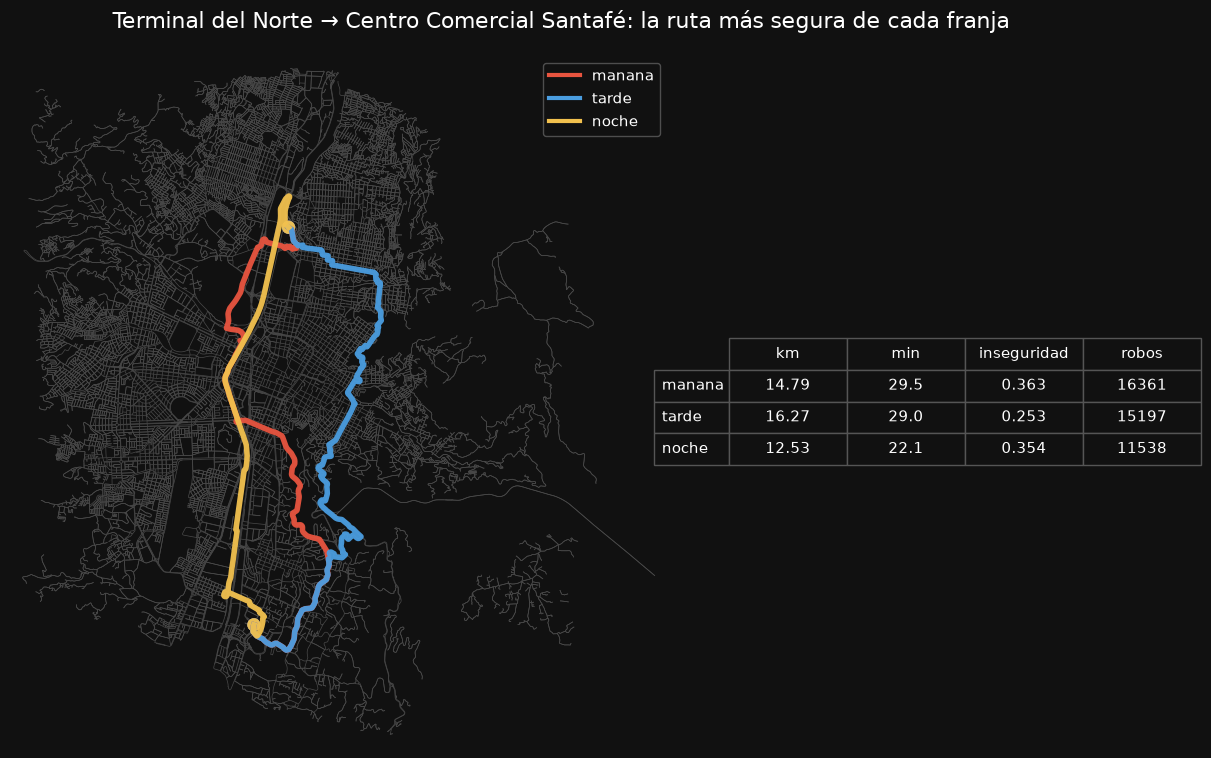

In [37]:
fig = plt.figure(figsize=(16, 9), facecolor=COLOR_FONDO)
rejilla = fig.add_gridspec(1, 2, width_ratios=[1.6, 1], wspace=0.02)

eje_mapa = fig.add_subplot(rejilla[0, 0])
# margen=1.2 -> se ve el valle entero alrededor de la ruta, pero sin los
# corregimientos. Con recortar=False sale el municipio completo y la ruta
# queda arrinconada en una esquina: probado, y no se lee.
dibujar_rutas(caminos_franja, etiquetas=list(FRANJAS),
              margen=1.2, ax=eje_mapa)

eje_tabla = fig.add_subplot(rejilla[0, 1])
# Nombres cortos: en la figura no hay sitio para "inseguridad_media" y la
# celda recorta el texto sin avisar.
tabla_en_eje(eje_tabla, tabla_franjas.round(3).rename(columns={
    "distancia_km": "km", "tiempo_min": "min",
    "inseguridad_media": "inseguridad", "robos_cerca": "robos"}))

fig.suptitle(f"{ORIGEN} → {DESTINO}: la ruta más segura de cada franja",
             color="w", fontsize=16, y=0.93)

fig.savefig(CARPETA_SALIDA / "figura_informe.png", dpi=200,
            facecolor=COLOR_FONDO, bbox_inches="tight")
print(f"guardado: {CARPETA_SALIDA / 'figura_informe.png'}")
plt.show()

### 15.4 Dónde exactamente se pone fea la ruta

Es una vista por tramos donde cambia el color en las zonas mas inseguras


guardado: salidas\ruta_inseguridad.png


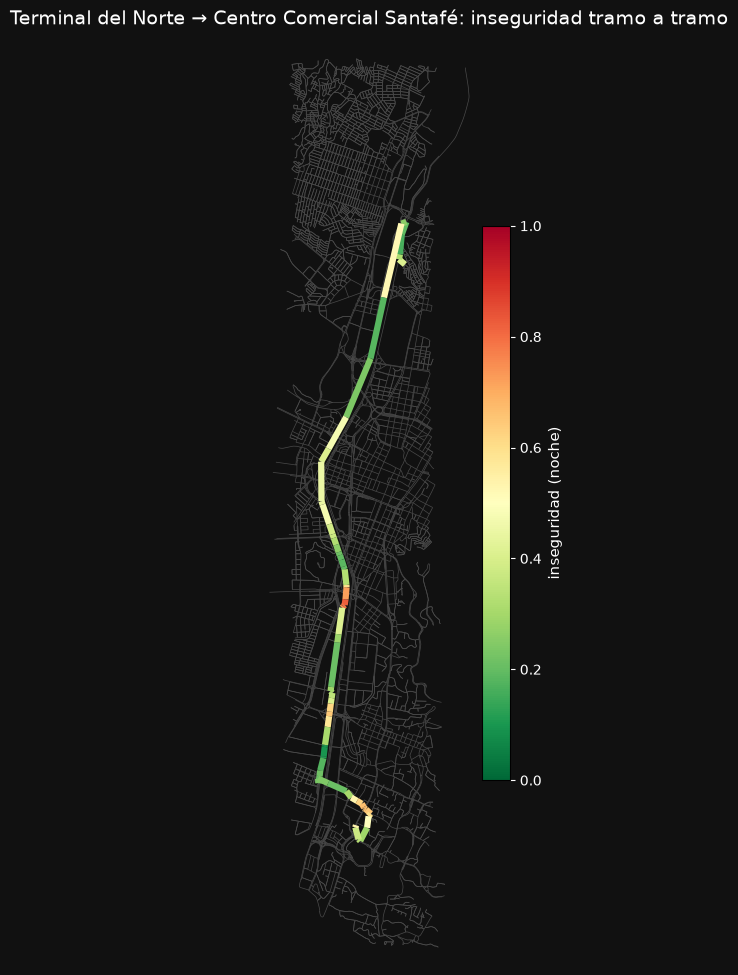


Los cinco tramos más inseguros de la ruta (noche):


,,nombre_via,distancia_m,inseguridad,tiene_camara
origen,destino,,,,
359753556,3688474314,Autopista Sur,93.343,0.824,0
3688474314,359753508,Carrera 50,33.776,0.797,0
359753508,359754175,Carrera 50,26.352,0.734,0
359749248,359753556,Autopista Sur,196.090,0.719,0
394238450,394238452,Calle 5 Sur,16.858,0.675,0


In [38]:
FRANJA_DETALLE = FRANJA_ACTUAL
camino_detalle, _ = ruta_silenciosa(ORIGEN, DESTINO,
                                    franja=FRANJA_DETALLE, criterio="seguridad")

_, peores = mapa_inseguridad(camino_detalle, FRANJA_DETALLE,
                             titulo=f"{ORIGEN} → {DESTINO}: inseguridad tramo a tramo",
                             archivo="ruta_inseguridad.png")
plt.show()

# Lo que habría dicho el tooltip
print(f"\nLos cinco tramos más inseguros de la ruta ({FRANJA_DETALLE}):")
display(peores.round(3))

### 15.5 El mapa de la inseguridad

Este no es un mapa de rutas, es el mapa de **datos**

In [39]:
import folium
from folium.plugins import HeatMap

MUESTRA_ROBOS = 25_000        # por franja
CORTES = [0.2, 0.4, 0.6, 0.8]                                   # 5 grupos
COLORES_INSEGURIDAD = ["#1a9850", "#a6d96a", "#fee08b", "#fc8d59", "#d73027"]

mapa = folium.Map(location=[6.25, -75.57], zoom_start=12, tiles="cartodbpositron")

# Coordenadas en grados de los dos extremos de cada calle. .loc con una lista
# respeta el orden, así que las tres tablas quedan alineadas fila a fila.
grados = nodos.set_index("id_nodo")[["lat", "lon"]]
extremo_a = grados.loc[aristas["origen"]].values
extremo_b = grados.loc[aristas["destino"]].values

for franja in FRANJAS:
    visible = (franja == FRANJA_ACTUAL)      # solo una capa encendida al abrir

    # ---------- calles, de verde a rojo ----------
    capa_vias = folium.FeatureGroup(name=f"Vías · {franja}", show=visible)
    grupo = np.digitize(aristas[f"inseguridad_{franja}"].values, CORTES)
    for g, color in enumerate(COLORES_INSEGURIDAD):
        indices = np.where(grupo == g)[0]
        if len(indices) == 0:
            continue
        # UNA PolyLine con todos los segmentos del grupo. Folium acepta una
        # lista de listas de puntos y la dibuja como multi-línea.
        folium.PolyLine([[list(extremo_a[i]), list(extremo_b[i])] for i in indices],
                        color=color, weight=2, opacity=0.75).add_to(capa_vias)
    capa_vias.add_to(mapa)

    # ---------- robos ----------
    robos_franja = robos[robos["franja"] == franja]
    muestra = robos_franja.sample(min(len(robos_franja), MUESTRA_ROBOS), random_state=0)
    capa_robos = folium.FeatureGroup(name=f"Robos · {franja}", show=visible)
    HeatMap(muestra[["latitud", "longitud"]].values.tolist(),
            radius=9, blur=13, min_opacity=0.25).add_to(capa_robos)
    capa_robos.add_to(mapa)

    print(f"  {franja:8s} {len(robos_franja):>7,} robos "
          f"({len(muestra):,} dibujados)")

# ---------- cámaras ----------
# Son 51: aquí sí se puede permitir un marcador por cámara, con su tooltip.
capa_camaras = folium.FeatureGroup(name="Cámaras", show=True)
for _, c in camaras.iterrows():
    folium.CircleMarker([c["latitud"], c["longitud"]], radius=4,
                        color="#2b83ba", fill=True, fill_opacity=0.9,
                        tooltip="Cámara").add_to(capa_camaras)
capa_camaras.add_to(mapa)

folium.LayerControl(collapsed=False).add_to(mapa)

ARCHIVO_MAPA = CARPETA_SALIDA / "mapa_seguridad.html"
mapa.save(ARCHIVO_MAPA)
print(f"\nguardado: {ARCHIVO_MAPA}  ({ARCHIVO_MAPA.stat().st_size/1e6:.1f} MB)")
print("Ábrelo en el navegador: dentro de Jupyter puede salir en blanco si el "
      "notebook no está firmado.")

  manana    44,472 robos (25,000 dibujados)
  tarde     51,150 robos (25,000 dibujados)
  noche     74,834 robos (25,000 dibujados)

guardado: salidas\mapa_seguridad.html  (9.0 MB)
Ábrelo en el navegador: dentro de Jupyter puede salir en blanco si el notebook no está firmado.
